In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import seaborn as sns
import bambi as bmb
import arviz as az
az.rcParams['stats.ci_prob'] = .95
from os import listdir, makedirs
import pickle
import ast

import logging
logger = logging.getLogger('pymc')
logger.setLevel(logging.ERROR)
pd.options.mode.chained_assignment = None  # default='warn'

In [2]:
# Data and figure path
DATA_PATH = '../data'
TRANSITION_RESULTS_PATH = '../results/transition-influence'
MODEL_RESULTS_PATH = '../results/model_fits.csv'
MODEL_REPRESENATIONS_PATH = '../results/fit_agent_representations'
FIG_PATH = '../figs'
makedirs(FIG_PATH, exist_ok=True)

# Subjects to exclude based on preregistered criterion
IDS_TO_EXCLUDE = [301, 303, 305, 327, 334, 352, 359, 362, 370, 372, 390, 404]

# Start -> Terminal for each condition
BETWEEN_ORDER = [2,3,0,1] # incongruent = between category
WITHIN_ORDER = [0,1,2,3]  # congruent = within category

CONDITION_COLORS = [
    '#FBAF00', # incongruent
    '#00AF54'  # congruent
]

CONDITION_LABELS = [
    'Category Incongruent',
    'Category Congruent'
]

TRANSITION_COLORS = {
    'spurious': '#FF0000', # spurious
    'causal': '#FFC100'    # causal
}

FREQUENCY_COLORS = [
    '#006C3E', # infrequent
    '#51DBA0'  # frequent
]

NOVELTY_COLORS = [
    '#32006b', # novel
    '#9251db'  # old
]

FF_MODEL_COLORS = {
    'mb-ff': '#C0E88F',
    'sf-ff': '#D65EB0',
    'sf-ff-decay': "#776b8c",
    'sf-ff-l1reg': "#af9cd0",
    'sf-ff-nonlin': "#b382a0"
}
FF_MODEL_LABELS = {
    'sf-ff': 'Feature (SF)',
    'mb-ff': 'Feature (MB)',
    'sf-ff-decay': r'Feature (SF, $λ$)',
    'sf-ff-l1reg': r'Feature (SF, $λ_{\mathregular{L1}}$)',
    'sf-ff-nonlin': r'Feature (SF, $κ$)'
}

MODEL_COLORS = {
    'null': 'grey',
    'ss': '#9cd8ff',
    'ss-sampler': '#3DB2FF',
    'ff': '#FF2442' 
}

MODEL_LABELS = [
    'Null',
    'Conjunctive',
    'Conjunctive (Sampler)',
    'Feature-based',
]

# Helper Functions

In [3]:
def info_from_fname(fname, field):
    """
    Get information from fname using field key

    Arguments
    ---------
    fname : str
        File name
    field : str
        Field key to get value for
    
    Returns
    -------
    field_value : str
        Value for specified field
    """
    key_vals = [
        (f.split('-')[0], '-'.join(f.split('-')[1:]))
        for f in fname.split('.')[0].split('_')
        ]
    fname_info = {key: val for key, val in key_vals}
    field_value = fname_info[field]
    return field_value

def load_from_dir(data_path, na_values=[]):
    """
    Load data from all CSV files in a directory.

    Arguments
    ---------
    data_path : str
        Path to directory containing CSV files
    na_values : list
        List of values to treat as NaN

    Returns
    -------
    df : pandas.DataFrame
        Concatenated DataFrame of all CSV files
    """
    df = []
    for f in listdir(data_path):
        if '.csv' in f:
            df.append(pd.read_csv(f'{data_path}/{f}', na_values=na_values))
    df = pd.concat(df)
    return df

def convert_str_to_array(array_string):
    """
    Convert a string representation of an array to a numpy array.

    Arguments
    ---------
    array_string : str
        The string representation of the array.

    Returns
    -------
    arr : numpy.ndarray
        The numpy array representation of the array.
    """
    array_string = array_string.replace(' ', ',').replace(',,', ',')
    arr = ast.literal_eval(array_string)
    arr = np.array(arr)
    return arr

def extract_rt(rt_str, i=-1):
    """
    Extract reaction time from selection times string array.

    Arguments
    ---------
    rt_str : str
        The string array of selection times.
    i : int
        The index of the reaction time to extract.

    Returns
    -------
    rt : float
        The extracted reaction time.
    """
    rt = convert_str_to_array(rt_str)[i]
    return rt

def identify_step(state):
    """
    Identify the step from which inference is made.

    Arguments
    ---------
    state : numpy.ndarray
        The state array.

    Returns
    -------
    step : int
        The step from which inference is made.
    """
    if np.any(np.isin([3, 4], state)):
        return 1
    elif np.any(np.isin([2, 5], state)):
        return 2

def recode_target(row, feature_tmat, instance_tmat):
    """
    Recode the target as if were fully semantic congruent

    Arguments
    ---------
    row : pandas.Series
        Row of the DataFrame containing the target information.
    feature_tmat : numpy.ndarray
        Feature transition matrix.
    instance_tmat : numpy.ndarray
        Instance transition matrix.

    Returns
    -------
    corr_comp_succ : numpy.ndarray
        The recoded target array.
    """
    corr_comp = row.correct_composition_arr
    corr_comp_succ = get_successor(
        corr_comp,
        feature_tmat[0],
        instance_tmat,
        start_step = row.step,
        n_steps = row.n_steps
    )
    return corr_comp_succ
    

def set_axis_ratio(ax, ratio=1):
    """
    Make axis aspect ratio square
    
    Arguments
    ---------
    ax : matplotlib.Axes
        matplotlib axis to transform
    ratio : int or float
        ratio of y- to x-axis
        
    Returns
    -------
    None
    """
    ax.set_aspect(ratio/ax.get_data_ratio(), adjustable='box')
    
    
def add_block_col(df):
    """
    Add block column to data frame, and trial number by block
    
    Arguments
    ---------
    df : pandas.DataFrame
        data frame to add block to
        
    Returns
    -------
    None
    """

    # Label block
    df['block'] = (df['t'] > np.max(df['t'])/2 ).astype(int) + 1

    # Label trial number within block
    df['t_block'] = df['t'].copy()
    idx = df['block'] == 2
    df.loc[idx, 't_block'] -= np.max(df.loc[np.logical_not(idx), 't'])

    # Label quarter of phase
    df['quarter'] = 4
    n_per_block = np.max(df['t_block'])
    idx = df['t'] < n_per_block/2
    df.loc[idx, 'quarter'] = 1
    idx = np.logical_not(idx) & (df['block'] == 1)
    df.loc[idx, 'quarter'] = 2
    idx = (df['t_block'] < n_per_block/2) & (df['block'] == 2)
    df.loc[idx, 'quarter'] = 3
    
def drop_invalid_data(df, excluded_ids=[]):
    """
    Drop invalid data (excluded IDs and missed trials)
    
    Arguments
    ---------
    df : pandas.DataFrame
        data frame to drop data from
    excluded_ids : list
        list of IDs to exclude
        
    Returns
    -------
    None
    """
    
    # Excluded subjects
    df = df.loc[np.isin(df['id'], excluded_ids, invert=True)]
    df = df.reset_index(drop=True)
    
    # Missed choices
    if 'action' in df.columns:
        df = df.loc[df['action'] != -1]

def convert_state_str(state_str):
    """
    Convert a string representation of a state to a numpy array.

    Arguments
    ---------
    state_str : str
        The string representation of the state.

    Returns
    -------
    state_arr : numpy.ndarray
        The numpy array representation of the state
    """
    state_str = state_str[1:-1].split(' ')
    state_arr = np.array(state_str, dtype=int)
    return state_arr
        
def get_frequent_targets(df):
    df['freq'] = 0
    idx = (
        (df['target'] == '[2 5 0 0]') |
        (df['target'] == '[5 2 0 0]') |
        (df['target'] == '[0 0 2 5]') |
        (df['target'] == '[0 0 5 2]') |
        (df['target'] == '[1 6 0 0]') |
        (df['target'] == '[6 1 0 0]') |
        (df['target'] == '[0 0 1 6]') |
        (df['target'] == '[0 0 6 1]') 
    )
    df.loc[idx, 'freq'] = 1


def get_successor(state, feature_tmat, instance_tmat, start_step, n_steps=1):
    """
    Get successor state.

    Arguments
    ---------
    state : numpy.Array
        State array to get successor of
    feature_tmat : numpy.Array
        Feature transition matrix. Should be 3D with dimensions 
        [step, feature, successor_feature]
    instance_tmat : numpy.Array
        Instance transition matrix. Should be 2D with dimensions
        [instance, successor_instance]
    start_step : int
        Step to start from in feature transition matrix
    n_steps : int
        Number of steps to get successor over

    Returns
    -------
    succ : numpy.Array
        Successor state array
    """
    for step in range(n_steps):
        succ = np.zeros_like(state, dtype=int)
        for feat in range(len(state)):
            if state[feat] != 0:
                inst = state[feat] - 1
                feat_new = np.random.choice(
                    np.arange(len(feature_tmat[0])),
                    p = feature_tmat[start_step + step - 1][feat]
                    )
                succ[feat_new] = np.random.choice(
                    np.arange(len(instance_tmat)) + 1,
                    p = instance_tmat[inst]
                    )
        state = succ
    return succ

def get_n_transitions_to_target(row, feature_tmat, instance_tmat):
    """
    Get number of possible causal inferences on a trial.

    Arguments
    ---------
    row : pandas.Series
        Row of data frame to get number of transitions for. Should
        contain columns 'condition', 'step', 'n_steps',
        'correct_composition_arr', 'target_arr', and 'options_comb_arr'
    feature_tmat : numpy.Array
        Feature transition matrix. Should be 4D with dimensions
        [condition, step, feature, successor_feature]
    instance_tmat : numpy.Array
        Instance transition matrix. Should be 2D with dimensions
        [instance, successor_instance]

    Returns
    -------
    n_causal : int
        Number of possible causal inferences on the trial
    """

    # Unpack information from row
    condition = row.condition
    step = row.step
    n_steps = row.n_steps
    corr_comp = row.correct_composition_arr
    target = row.target_arr
    options_comb = row.options_comb_arr
    

    # Get successor of the correct composition
    corr_comp_succ = get_successor(
        corr_comp*options_comb,
        feature_tmat[condition],
        instance_tmat,
        start_step = step,
        n_steps = n_steps
    )

    # Number of possible causal transitions that can be inferred
    causal = (
        (corr_comp_succ == target) &
        (target != 0)
    )
    n_causal = np.sum(causal)

    return n_causal

def plot_hdi(
        ax,
        posterior,
        label = False,
        label_loc = 'left',
        color = 'k',
        chance_color = 'red',
        xlim = False
    ):
    hdi = az.hdi(posterior)
    sns.kdeplot(
        posterior,
        color='white',
        fill = True,
        lw=.5,
        alpha=1,
        #bw_adjust=.5,
        ax=ax
    )
    sns.kdeplot(
        posterior,
        color='k',
        lw=.5,
        #bw_adjust=.5,
        ax=ax
    )
    sns.kdeplot(
        posterior,
        color = color,
        #bw_adjust=.5,
        clip=hdi,
        fill=True,
        lw=1,
        edgecolor='k',
        alpha=1,
        ax=ax
    )

    
    ax.set_yticks([])
    ax.set_ylabel(None)
    if label:
        ax.set_title(label, fontsize = 7, pad = 3, loc=label_loc)
    if xlim:
        ax.set_xlim(xlim)
    ax.set_xticks([])
    #ax.set_xticklabels(ax.get_xticks(), fontsize=6)
    #ax.axvline(0, color='k', linestyle='-', linewidth=3, zorder=0)
    ax.axvline(0, color=chance_color, linestyle='-')
    ax.set_facecolor((1, 1, 1, 0))
    #ax.set_facecolor('.7')

def data_summary(df, group_vars, y_var, x_var='1', seed=0, fname=False):
    """
    Get mean and 95% HDI of Bayesian models based on group variables.
    
    Arguments
    ---------
    df : pd.DataFrame
        Data frame to summarize.
    group_vars : list
        List of variables to group by.
    y_var : str
        Dependent variable.
    x_var : str
        Independent variable. If '1', then only an intercept is fit.
    seed : int
        Random seed for reproducibility.
    fname : str
        File name to load/save results.

    Returns
    -------
    summaries : dict
        Dictionary of group variable combinations and their summaries.
    """

    # Check if saved results already exist
    if fname:
        try:
            with open(fname, 'rb') as f:
                summaries = pickle.load(f)
            return summaries
        except FileNotFoundError:
            pass
    
    # Compute summaries
    summaries = {}
    group_combs = df[group_vars].drop_duplicates().copy()
    group_combs = group_combs.sort_values(by=list(group_combs.columns))
    group_combs = np.array(group_combs)
    for comb in group_combs:

        # Fit model
        idx = np.all(df[group_vars] == comb, axis=1)
        model = bmb.Model(f'{y_var} ~ {x_var}', df.loc[idx])
        fitted = model.fit(random_seed=seed)

        # Generate HDI from posterior predictions
        post_intercept = fitted.posterior['Intercept'].values.flatten()
        if x_var == '1':
            post_slope = np.zeros(len(post_intercept))
            x = 0
        else:
            post_slope = fitted.posterior[x_var].values.flatten()
            x = np.unique(df.loc[idx, x_var])
        post_preds = np.array([
            intercept + slope*x
            for intercept, slope in zip(post_intercept, post_slope)
        ])
        hdi = az.hdi(post_preds)

        # Get mean point or line prediction
        pred_mean = np.mean(post_intercept)
        if x_var == '1':
            pred_mean = [0, pred_mean]
        else:
            x_range = np.array([np.min(x), np.max(x)])
            pred_mean += np.mean(post_slope)*x_range
            pred_mean = [x_range, pred_mean]

        # Get mean and 95% HDI of posterior predictions
        post_summary = {
            'mean': pred_mean,
            'hdi': hdi
        }
        
        # Add to summaries
        if len(group_vars) > 1:
            key = tuple(comb)
        else:
            key = comb[0]
        summaries[key] = post_summary

    # Save results
    if fname:
        if '/' in fname:
            makedirs('/'.join(fname.split('/')[:-1]), exist_ok=True)
        with open(fname, 'wb') as f:
            pickle.dump(summaries, f)

    return summaries


def unpack_summary_timeseries(stats_summary):
    """
    Unpack summary stats for time series data.

    Arguments
    ---------
    stats_summary : dict
        Dictionary of summary stats.
    
    Returns
    -------
    series : dict
        Dictionary of unpacked summary timeseries stats.
    """

    # Initialize dictionary to store summary stats
    series = {}
    levels = np.unique(np.array(list(stats_summary.keys()))[:, :-1], axis=0)
    for level in levels:
        series[*level, 'mean'] = []
        series[*level, 'hdi'] = []
        series[*level, 'x'] = []

    # Unpack mean and HDI for each level
    for key in stats_summary.keys():
        if len(key) > 2:
            series_key = [str(k) for k in key[:-1]]
        else:
            series_key = key[:-1]
        series[*series_key, 'mean'].append(stats_summary[key]['mean'][1])
        series[*series_key, 'hdi'].append(stats_summary[key]['hdi'])
        series[*series_key, 'x'].append(key[-1])

    # Store as array
    for key in series.keys():
        series[key] = np.array(series[key])

    # Sort values by x
    for level in levels:
        idx = np.argsort(series[*level, 'x']) 
        series[*level, 'mean'] = series[*level, 'mean'][idx]
        series[*level, 'hdi'] = series[*level, 'hdi'][idx]
        series[*level, 'x'] = series[*level, 'x'][idx]

    return series

def plot_by_categorical(
        df,
        x_var,
        y_var,
        x_label = None,
        y_label = None,
        x_tick_labels = [],
        y_lim = None,
        palette = None,
        chance = 1,
        summary_fname = False,
        fname = False,
        posterior = [],
        posterior_config = {}
        ):
    
    # Average y for each participant and grouping x variable
    plot_df = df[['id', x_var,  y_var]]
    plot_df = plot_df.groupby(['id', x_var])
    plot_df = plot_df.mean()
    plot_df = plot_df.reset_index()
    
    # Get mean and 95% HDI 
    summary = data_summary(
        plot_df,
        [x_var],
        y_var,
        seed = 2334,
        fname = summary_fname
    )
    
    fig, ax = plt.subplots(figsize=(2.5, 3))

    # Plot data
    ax.axhline(.5, color='black', linestyle='--')
    sns.swarmplot(
        data = plot_df,
        x = x_var,
        y = y_var,
        palette = palette,
        order = [1, 0],
        s = 3,
        zorder = 0
    )

    # Plot 95% HDI
    for i, key in enumerate(summary.keys()):
        ax.vlines(i, *summary[key]['hdi'], color='black', linewidth=3)
        ax.plot(i, summary[key]['mean'][1], 'ok', linewidth=3, markersize=7)

    # Format
    ax.set_xticklabels(x_tick_labels, fontsize=7)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_ylim(y_lim)
    set_axis_ratio(ax, 2)

     # Inset interaction posterior plot with HDI
    if len(posterior) > 0:
        inset_ax = inset_axes(
            ax,
            width = '70%',
            height = '20%',
            bbox_to_anchor = (-.17, -.34, .95, 0.48),
            bbox_transform = ax.transAxes
        )
        plot_hdi(
            inset_ax,
            posterior.values.flatten(),
            **posterior_config
        )

    fig.tight_layout()
    if fname:
        fig.savefig(fname, bbox_inches='tight')
    

def plot_by_condition_and_categorical(
        df,
        x_var,
        y_var,
        title = None,
        x_label = None,
        y_label = None,
        x_tick_labels = [], 
        y_lim = None,
        chance = 1,
        summary_fname = False,
        fname = False,
        posterior = [],
        posterior_config = {},
        bbox_to_anchor = (.03, -.34, .95, 0.48)
        ):
    """
    Plot by condition and some categorical variable.

    Arguments
    ---------
    df : pd.DataFrame
        Data frame to plot.
    x_var : str
        Categorical variable to plot on x-axis with condition
    y_var : str
        Variable to plot of the y axis
    title : str
        Plot title
    x_label : str
        Label for x-axis.
    y_label : str
        Label for y-axis.
    x_tick_labels : list
        List of x-tick labels.
    y_lim : tuple
        y-axis limits.
    chance : float
        Value to plot as chance level with dashed line. If None,
        then no chance line is plotted.
    summary_fname : str
        File name to save/load summary stats.
    fname : str
        File name to save plot.
    posterior : np.array
        Posterior values to plot.
    posterior_config : dict
        Configuration for posterior plot (plot_hdi).
    bbox_to_anchor : tuple
        Position of posterior bbox

    Returns
    -------
    None
    """
    
    # Average y for each participant and grouping x variable
    plot_df = df[['id', x_var, 'sem_congruent', y_var]].copy()
    plot_df = plot_df.groupby(['id', x_var, 'sem_congruent'])
    plot_df = plot_df.mean()
    plot_df = plot_df.reset_index()
    
    # Get mean and 95% HDI timeseries
    summary = data_summary(
        plot_df,
        ['sem_congruent', x_var],
        y_var,
        seed = 2334,
        fname = summary_fname
    )

    # Get x labels
    x_labels = np.unique(plot_df[x_var])
    n_x_labels = len(x_labels)
    plot_df[x_var] = plot_df[x_var].astype('category').cat.codes

    # Group by condition and frequency for x-tick label
    plot_df['group'] = plot_df['sem_congruent']*n_x_labels + plot_df[x_var]

    fig, ax = plt.subplots(figsize=(2.5, 3))

    if chance is not None:
        ax.axhline(chance, c='.5', linestyle='--')
    sns.lineplot(
        data = plot_df,
        x = 'group',
        y = y_var,
        hue = 'id',
        palette = condition_id_palette,
        linewidth = 1,
        ax = ax
    )

    # Plot 95% HDI
    for i, key in enumerate(summary.keys()):
        x = key[0]*n_x_labels + key[1]
        ax.vlines(i, *summary[key]['hdi'], color='black', linewidth=3)
        
    # Plot means 
    for cond in [0, 1]:
        x = np.arange(n_x_labels) + cond*n_x_labels
        y = np.array([
            summary[cond, x]['mean'][1]
            for x in x_labels
            ])
        ax.plot(x, y, '-ok', linewidth=3, markersize=7)

    # Format main axis
    ax.set_xlim([
        np.min(np.unique(plot_df['group'])) - .5,
        np.max(np.unique(plot_df['group'])) + .5
        ])
    ax.get_legend().remove()
    ax.set_xticks(np.unique(plot_df['group']))
    ax.set_xticklabels(x_tick_labels*2, fontsize=7)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_ylim(y_lim)
    ax.set_title(title, loc='left')
    set_axis_ratio(ax, 2)

    # Inset interaction posterior plot with HDI
    if len(posterior) > 0:
        inset_ax = inset_axes(
            ax,
            width = '70%',
            height = '20%',
            bbox_to_anchor = bbox_to_anchor,
            bbox_transform = ax.transAxes
        )
        plot_hdi(
            inset_ax,
            posterior.values.flatten(),
            **posterior_config
        )

    fig.tight_layout()
    if fname:
        fig.savefig(fname, bbox_inches='tight')

def plot_by_categorical(
        df,
        x_var,
        y_var,
        title = None,
        x_label = None,
        y_label = None,
        x_tick_labels = [], 
        y_lim = None,
        chance = 1,
        summary_fname = False,
        fname = False,
        posterior = [],
        posterior_config = {},
        bbox_to_anchor = (.03, -.34, .95, 0.48),
        palette = None
        ):
    """
    Plot by some categorical variable.

    Arguments
    ---------
    df : pd.DataFrame
        Data frame to plot.
    x_var : str
        Categorical variable to plot on x-axis
    y_var : str
        Variable to plot of the y axis
    title : str
        Plot title
    x_label : str
        Label for x-axis.
    y_label : str
        Label for y-axis.
    x_tick_labels : list
        List of x-tick labels.
    summary_fname : str
        File name to save/load summary stats.
    fname : str
        File name to save plot.
    posterior : np.array
        Posterior values to plot.
    posterior_config : dict
        Configuration for posterior plot (plot_hdi).
    bbox_to_anchor : tuple
        Position of posterior bbox
    palette : str
        Palette for x-axis variable

    Returns
    -------
    None
    """
    
    # Average y for each participant and grouping x variable
    plot_df = df[['id', x_var, y_var]]
    plot_df = plot_df.groupby(['id', x_var])
    plot_df = plot_df.mean()
    plot_df = plot_df.reset_index()
    
    # Get mean and 95% HDI timeseries
    summary = data_summary(
        plot_df,
        [x_var],
        y_var,
        seed = 2334,
        fname = summary_fname
    )

    fig, ax = plt.subplots(figsize=(2.5, 3))

    ax.axhline(chance, c='.5', linestyle='--')
    sns.swarmplot(
        data = plot_df,
        x = x_var,
        y = y_var,
        hue = x_var,
        palette = CONDITION_COLORS,
        s = 2.5,
        zorder = 0
    )

    # Plot 95% HDI
    for i, key in enumerate(summary.keys()):
        ax.vlines(key, *summary[key]['hdi'], color='black', linewidth=3)
        
    # Plot means 
    for var in summary.keys():
        ax.plot(
            var,
            summary[var]['mean'][1],
            'ok',
            linewidth = 3,
            markersize = 7
        )

    # Format main axis
    ax.set_xlim([np.min(np.unique(plot_df[x_var])) - .5, np.max(np.unique(plot_df[x_var])) + .5])
    ax.set_xticks(np.unique(plot_df[x_var]))
    ax.set_xticklabels(x_tick_labels, fontsize=7)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_ylim(y_lim)
    ax.set_title(title, loc='left')
    ax.get_legend().remove()
    set_axis_ratio(ax, 2)

    # Inset interaction posterior plot with HDI
    if len(posterior) > 0:
        inset_ax = inset_axes(
            ax,
            width = '70%',
            height = '20%',
            bbox_to_anchor = bbox_to_anchor,
            bbox_transform = ax.transAxes
        )
        plot_hdi(
            inset_ax,
            posterior.values.flatten(),
            **posterior_config
        )

    fig.tight_layout()
    if fname:
        fig.savefig(fname, bbox_inches='tight')

In [4]:
def to_class_label(model_label):
    if 'ff' in model_label:
        return 'ff'
    elif 'ss-sampler' in model_label:
        return 'ss-sampler'
    elif 'ss' in model_label:
        return 'ss'
    elif 'null' in model_label:
        return 'null'
    else:
        return model_label



# Load model fits

In [5]:
model_fits_df = pd.read_csv(
    MODEL_RESULTS_PATH,
    na_values=['', 'NaN', None],
    keep_default_na = False
)
idx = np.isin(model_fits_df['id'], IDS_TO_EXCLUDE, invert=True)
model_fits_df = model_fits_df.loc[idx]
model_fits_df = model_fits_df.reset_index(drop=True)
model_fits_df = model_fits_df.drop_duplicates()

model_fits_df['bias_magnitude'] = model_fits_df['bias_magnitude'].fillna(0)

# replace NA values
model_fits_df = model_fits_df.fillna(-999)

# Label the broader model class
model_fits_df['model_class'] = model_fits_df['model_label'].apply(to_class_label)

model_fits_df

,id,model_label,success,n_starts,nll,aic,alpha,beta,bias_magnitude,conjunctive_starts,conjunctive_successors,conjunctive_composition,memory_sampler,sampler_feature_weight,sampler_recency_weight,sampler_specificity,lmbd_l1,lmbd,inference_power,model_class
0,300,mb-ff,True,8,429.511916,863.023832,0.014394,1.428355,0.0,-999,-999,-999,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.0,-999.000000,ff
1,300,mb-ff-bias,True,8,429.511916,865.023832,0.014394,1.428357,0.0,-999,-999,-999,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.0,-999.000000,ff
2,300,mb-ss,True,8,431.479658,866.959315,0.079072,0.612903,0.0,True,True,True,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.0,-999.000000,ss
3,300,mb-ss-sampler,True,8,428.882212,865.764424,0.000100,0.549725,0.0,True,True,-999,True,0.142857,0.0,47.104792,-999.000000,-999.0,-999.000000,ss-sampler
4,300,null,True,0,432.523841,865.047681,-1.000000,-1.000000,0.0,-999,-999,-999,-999,-999.000000,-999.0,-999.000000,-1.000000,-999.0,-999.000000,null
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1525,414,sf-ff-decay,True,10,337.280122,680.560243,0.161661,17.080643,0.0,-999,-999,-999,-999,-999.000000,-999.0,-999.000000,-999.000000,1.0,-999.000000,ff
1526,414,sf-ff-l1reg,True,8,335.873666,677.747332,0.326127,10.303085,0.0,-999,-999,-999,-999,-999.000000,-999.0,-999.000000,0.182213,-999.0,-999.000000,ff
1527,414,sf-ff-nonlin,True,8,337.213267,680.426534,0.337456,4.422570,0.0,-999,-999,-999,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.0,0.181982,ff
1528,414,sf-ss,True,8,378.254470,760.508940,0.957528,1.977228,0.0,True,True,True,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.0,-999.000000,ss


## Get best fitting models

In [6]:
model_fits_df['best_fit'] = 0
for subj in np.unique(model_fits_df['id']):
    idx = model_fits_df['id'] == subj
    subj_fits = model_fits_df.loc[idx]
    
    # Get best fitting model
    min_aic = np.argmin(subj_fits['aic'])
    subj_fits['best_fit'] = np.eye(np.sum(idx), dtype=int)[min_aic]    
    model_fits_df.loc[idx] = subj_fits

# Select the best fits
idx = model_fits_df['best_fit'] == 1
best_fits = model_fits_df.loc[idx]

# Label if the feature-based model is best fitting
best_fits['ff_fit'] = best_fits['model_class'] == 'ff'
best_fits['ff_fit'] = best_fits['ff_fit'].astype(int)

best_fits

,id,model_label,success,n_starts,nll,aic,alpha,beta,bias_magnitude,conjunctive_starts,...,memory_sampler,sampler_feature_weight,sampler_recency_weight,sampler_specificity,lmbd_l1,lmbd,inference_power,model_class,best_fit,ff_fit
5,300,sf-ff,True,7,429.379997,862.759994,0.066273,1.990263,0.000000,-999,...,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.000000,-999.000000,ff,1,1
24,302,sf-ff-bias-nonlin,True,8,268.813640,545.627281,0.167476,8.662632,0.894416,-999,...,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.000000,0.106869,ff,1,1
31,304,mb-ff-bias,True,7,212.662871,431.325741,0.022179,20.428754,0.673723,-999,...,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.000000,-999.000000,ff,1,1
59,306,sf-ss-sampler,True,7,429.934974,867.869949,0.272634,31.685567,0.000000,True,...,True,0.111111,0.0,1.209115,-999.000000,-999.000000,-999.000000,ss-sampler,1,0
67,307,sf-ff-bias-decay,True,8,297.561097,603.122193,0.328629,9.769525,0.601175,-999,...,-999,-999.000000,-999.0,-999.000000,-999.000000,0.687596,-999.000000,ff,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1467,409,sf-ff-nonlin,True,9,411.878498,829.756996,0.000506,516.749895,0.000000,-999,...,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.000000,0.000000,ff,1,1
1478,410,sf-ff-bias-l1reg,True,7,376.200861,760.401721,0.409346,4.322264,0.519995,-999,...,-999,-999.000000,-999.0,-999.000000,0.186266,-999.000000,-999.000000,ff,1,1
1497,411,sf-ff-nonlin,True,6,410.330350,826.660699,1.000000,1.738369,0.000000,-999,...,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.000000,0.003310,ff,1,1
1502,413,mb-ss,True,7,397.244183,798.488366,0.768484,1.617475,0.000000,True,...,-999,-999.000000,-999.0,-999.000000,-999.000000,-999.000000,-999.000000,ss,1,0


# Load data

In [7]:


FEATURE_REORDER = np.array([

        # Condition 1 (1I) - semantic congruent
        [

            # Step 1
            [0,1,2,3],

            # Step 2
            [0,1,2,3]

        ],

        # Condition 2 (1II) - semantic incongruent

        [
            # Step 1
            [3,2,1,0],

            # Step 2
            [2,3,0,1]

        ],

        # Condition 3 (2I) - semantic incongruent
        [

            # Step 1
            [2,3,0,1],

            # Step 2
            [3,2,1,0]

        ],

        # Condition 4 (3II) - semantic congruent
        [

            # Step 1
            [0,1,2,3],

            # Step 2
            [0,1,2,3]

        ],

        # Condition 5 (2II) - semantic congruent
        [

            # Step 1
            [0,1,2,3],

            # Step 2
            [0,1,2,3]

        ],

        # Condition 6 (3II) - semantic incongruent
        [
            # Step 1
            [2,3,0,1],

            # Step 2
            [3,2,1,0]

        ]
        
    ])


In [8]:
# Load data
training_df = load_from_dir(f'{DATA_PATH}/training', na_values='null')
add_block_col(training_df)
training_df = training_df.loc[training_df['valid_response'] == 1]
training_df = training_df.reset_index(drop=True)

# Exclude participants
idx = np.isin(training_df['id'], IDS_TO_EXCLUDE, invert=True)
training_df = training_df.loc[idx]
training_df = training_df.reset_index(drop=True)

# Reaction times
training_df['first_rt'] = training_df['rt'].apply(extract_rt, args=(0,))
training_df['last_rt'] = training_df['rt'].apply(extract_rt, args=(-1,))

# Frequent versus infrequent targets
get_frequent_targets(training_df)

# Add best fitting model
training_df = pd.merge(
    training_df,
    best_fits[['id', 'model_class', 'model_label', 'bias_magnitude']]
)

# Convert state columns
training_df['target_arr'] = training_df['target'].apply(convert_str_to_array)
training_df['options_arr'] = training_df['options'].apply(convert_str_to_array)
training_df['composition_arr'] = training_df['composition'].apply(convert_str_to_array)

# Identify which step inference is made from
training_df['step'] = training_df['options_arr'].apply(identify_step)

# Compute cumulative reward
training_df = training_df.sort_values(['id', 't'])
training_df = training_df.reset_index(drop=True)
training_df['cumulative_reward'] = training_df.groupby(
    'id')['reward'].cumsum()

# Compute cumulative reward by block
training_df = training_df.sort_values(['id', 't'])
training_df = training_df.reset_index(drop=True)
training_df['cumulative_reward_block'] = training_df.groupby(
    ['id', 'block'])['reward'].cumsum()

# Re-code so condition = 1 = semantic congruent
training_df['sem_congruent'] = 1 - training_df['between_cond'].astype(int)

training_df

,id,seed,condition,between_cond,phase,run,t,n_steps,target_comb,options_comb,...,model_class,model_label,bias_magnitude,target_arr,options_arr,composition_arr,step,cumulative_reward,cumulative_reward_block,sem_congruent
0,300,0,0,0,training,1,4,1,[1 1 0 0],[1 1 0 0],...,ff,sf-ff,0.000000,"[1, 6, 0, 0]","[[[2, 0, 0, 0], [5, 0, 0, 0]], [[0, 5, 0, 0], ...","[2, 5, 0, 0]",2,2,2,1
1,300,0,0,0,training,1,5,1,[1 1 0 0],[1 1 0 0],...,ff,sf-ff,0.000000,"[2, 5, 0, 0]","[[[3, 0, 0, 0], [4, 0, 0, 0]], [[0, 4, 0, 0], ...","[4, 4, 0, 0]",1,3,3,1
2,300,0,0,0,training,1,6,1,[1 1 0 0],[1 1 0 0],...,ff,sf-ff,0.000000,"[6, 1, 0, 0]","[[[2, 0, 0, 0], [5, 0, 0, 0]], [[0, 2, 0, 0], ...","[2, 2, 0, 0]",2,4,4,1
3,300,0,0,0,training,1,7,1,[1 1 0 0],[1 1 0 0],...,ff,sf-ff,0.000000,"[5, 2, 0, 0]","[[[3, 0, 0, 0], [4, 0, 0, 0]], [[0, 4, 0, 0], ...","[4, 4, 0, 0]",1,5,5,1
4,300,0,0,0,training,1,8,1,[1 1 0 0],[1 1 0 0],...,ff,sf-ff,0.000000,"[5, 2, 0, 0]","[[[4, 0, 0, 0], [3, 0, 0, 0]], [[0, 4, 0, 0], ...","[3, 4, 0, 0]",1,5,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14564,414,11,3,0,training,4,140,1,[0 0 1 1],[0 0 1 1],...,ff,sf-ff-bias-l1reg,0.438658,"[0, 0, 6, 6]","[[[0, 0, 0, 2], [0, 0, 0, 5]], [[0, 0, 5, 0], ...","[0, 0, 5, 5]",2,232,127,1
14565,414,11,3,0,training,4,141,1,[0 0 1 1],[0 0 1 1],...,ff,sf-ff-bias-l1reg,0.438658,"[0, 0, 2, 2]","[[[0, 0, 0, 4], [0, 0, 0, 3]], [[0, 0, 3, 0], ...","[0, 0, 3, 3]",1,234,129,1
14566,414,11,3,0,training,4,142,1,[0 0 1 1],[0 0 1 1],...,ff,sf-ff-bias-l1reg,0.438658,"[0, 0, 5, 5]","[[[0, 0, 4, 0], [0, 0, 3, 0]], [[0, 0, 0, 4], ...","[0, 0, 4, 4]",1,236,131,1
14567,414,11,3,0,training,4,143,1,[0 0 1 1],[0 0 1 1],...,ff,sf-ff-bias-l1reg,0.438658,"[0, 0, 6, 1]","[[[0, 0, 0, 5], [0, 0, 0, 2]], [[0, 0, 5, 0], ...","[0, 0, 5, 2]",2,238,133,1


In [9]:
FEATURE_TMAT = np.array([

        # Condition 1 (1I) - semantic congruent
        [

            # Step 1
            [[1,0,0,0],
             [0,1,0,0],
             [0,0,1,0],
             [0,0,0,1]],

            # Step 2
            [[1,0,0,0],
             [0,1,0,0],
             [0,0,1,0],
             [0,0,0,1]],

        ],

        # Condition 2 (1II) - semantic incongruent

        [
            # Step 1
            [[0,0,0,1],
             [0,0,1,0],
             [0,1,0,0],
             [1,0,0,0]],

            # Step 2
            [[0,0,1,0],
             [0,0,0,1],
             [1,0,0,0],
             [0,1,0,0]],

        ],

        # Condition 3 (2I) - semantic incongruent
        [

            # Step 1
            [[0,0,1,0],
             [0,0,0,1],
             [1,0,0,0],
             [0,1,0,0]],

            # Step 2
            [[0,0,0,1],
             [0,0,1,0],
             [0,1,0,0],
             [1,0,0,0]],

        ],

        # Condition 4 (3II) - semantic congruent
        [

            # Step 1
            [[1,0,0,0],
             [0,1,0,0],
             [0,0,1,0],
             [0,0,0,1]],

            # Step 2
            [[1,0,0,0],
             [0,1,0,0],
             [0,0,1,0],
             [0,0,0,1]],

        ],

        # Condition 5 (2II) - semantic congruent
        [

            # Step 1
            [[1,0,0,0],
             [0,1,0,0],
             [0,0,1,0],
             [0,0,0,1]],

            # Step 2
            [[1,0,0,0],
             [0,1,0,0],
             [0,0,1,0],
             [0,0,0,1]],

        ],

        # Condition 6 (3II) - semantic incongruent
        [
            # Step 1
            [[0,0,1,0],
             [0,0,0,1],
             [1,0,0,0],
             [0,1,0,0]],

            # Step 2
            [[0,0,0,1],
             [0,0,1,0],
             [0,1,0,0],
             [1,0,0,0]]

        ]
        
    ])

INSTANCE_TMAT = np.array([
            [1,0,0,0,0,0],
            [1,0,0,0,0,0],
            [0,1,0,0,0,0],
            [0,0,0,0,1,0],
            [0,0,0,0,0,1],
            [0,0,0,0,0,1]
        ])

In [10]:
# Load data
test_df = load_from_dir(f'{DATA_PATH}/test', na_values='null')
test_df = test_df.loc[test_df['valid_response'] == 1]
test_df = test_df.reset_index(drop=True)

# Exclude participants
idx = np.isin(test_df['id'], IDS_TO_EXCLUDE, invert=True)
test_df = test_df.loc[idx]
test_df = test_df.reset_index(drop=True)

# Reaction times
test_df['first_rt'] = test_df['rt'].apply(extract_rt, args=(0,))
test_df['last_rt'] = test_df['rt'].apply(extract_rt, args=(-1,))

# Frequent versus infrequent targets during training
get_frequent_targets(test_df)

# Get novel targets and options
test_df['novel_target'] = np.logical_not(
    (test_df['target_comb'] == '[1 1 0 0]') |
    (test_df['target_comb'] == '[0 0 1 1]')
)
test_df['novel_options'] = np.logical_not(
    (test_df['options_comb'] == '[1 1 0 0]') |
    (test_df['options_comb'] == '[0 0 1 1]')
)

# Convert state columns
test_df['target_arr'] = test_df['target'].apply(convert_str_to_array)
test_df['options_arr'] = test_df['options'].apply(convert_str_to_array)
test_df['options_comb_arr'] = test_df['options_comb'].apply(convert_str_to_array)
test_df['composition_arr'] = test_df['composition'].apply(convert_str_to_array)
test_df['correct_composition_arr'] = test_df['correct_composition'].apply(convert_str_to_array)

# Identify which step inference is made from
test_df['step'] = test_df['options_arr'].apply(identify_step)

# Get number of possible transitions to the target
test_df['n_transitions_to_target'] = test_df.apply(
    get_n_transitions_to_target,
    args = (FEATURE_TMAT, INSTANCE_TMAT),
    axis = 1
    )

# Get old (from training) trials
test_df['old'] = (
    np.logical_not(test_df['novel_options'] | test_df['novel_target']) &
    (test_df['n_transitions_to_target'] == 2)
)

# Add best fitting model
test_df = pd.merge(
    test_df,
    best_fits[['id', 'model_class', 'model_label', 'bias_magnitude']]
)

# Create column of recoded targets where features correspond not to stimulus features
# but to whether instances transition to each other or not
test_df['target_recoded_arr'] = test_df.apply(
    recode_target,
    args = (FEATURE_TMAT, INSTANCE_TMAT),
    axis = 1
)

# Get chance reward on trials with possible valid causal inferences
idx = test_df['n_transitions_to_target'] != 0
test_trials_df = test_df.loc[idx, [
    'target',
    'options_comb',
    'n_transitions_to_target'
]]
test_trials_df = test_trials_df.drop_duplicates()
test_trials_df = test_trials_df.reset_index(drop=True)
test_chance_reward = np.mean(test_trials_df['n_transitions_to_target']/2)

# Re-code so condition = 1 = semantic congruent
test_df['sem_congruent'] = 1 - test_df['between_cond'].astype(int)
        
test_df

,id,seed,condition,between_cond,phase,run,t,n_steps,target_comb,options_comb,...,composition_arr,correct_composition_arr,step,n_transitions_to_target,old,model_class,model_label,bias_magnitude,target_recoded_arr,sem_congruent
0,341,6,2,1,test,1,1,1,[1 0 1 0],[1 0 0 1],...,"[4, 0, 0, 3]","[3, 0, 4, 0]",1,1,False,ff,mb-ff,0.000000,"[2, 0, 5, 0]",0
1,341,6,2,1,test,1,2,2,[0 1 0 1],[1 0 0 1],...,"[3, 0, 0, 4]","[3, 0, 3, 0]",1,1,False,ff,mb-ff,0.000000,"[1, 0, 1, 0]",0
2,341,6,2,1,test,1,3,1,[1 1 0 0],[1 0 1 0],...,"[4, 0, 3, 0]","[0, 0, 4, 4]",1,1,False,ff,mb-ff,0.000000,"[0, 0, 5, 5]",0
3,341,6,2,1,test,1,4,1,[0 1 1 0],[1 0 1 0],...,"[5, 0, 2, 0]","[0, 2, 5, 0]",2,1,False,ff,mb-ff,0.000000,"[0, 1, 6, 0]",0
4,341,6,2,1,test,1,5,1,[1 0 1 0],[1 0 0 1],...,"[5, 0, 0, 5]","[0, 2, 0, 5]",2,1,False,ff,mb-ff,0.000000,"[0, 1, 0, 6]",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17645,330,3,3,0,test,2,170,1,[1 1 0 0],[1 1 0 0],...,"[4, 4, 0, 0]","[3, 3, 0, 0]",1,2,True,ff,sf-ff-bias-nonlin,0.727174,"[2, 2, 0, 0]",1
17646,330,3,3,0,test,2,171,1,[0 0 1 1],[0 0 1 1],...,"[0, 0, 3, 4]","[0, 0, 3, 4]",1,2,True,ff,sf-ff-bias-nonlin,0.727174,"[0, 0, 2, 5]",1
17647,330,3,3,0,test,2,172,1,[1 1 0 0],[1 1 0 0],...,"[3, 4, 0, 0]","[4, 3, 0, 0]",1,2,True,ff,sf-ff-bias-nonlin,0.727174,"[5, 2, 0, 0]",1
17648,330,3,3,0,test,2,173,2,[0 0 1 1],[0 0 1 1],...,"[0, 0, 3, 4]","[0, 0, 3, 4]",1,2,True,ff,sf-ff-bias-nonlin,0.727174,"[0, 0, 1, 6]",1


In [11]:
test_df['comp_spur_pred'] = 0
test_df['spurious_trial'] = 0
test_df['causal_trial'] = 0

for i in range(len(test_df)):
    
    # Get recoded target and composition arrays for this trial
    target = test_df.loc[i, 'target_recoded_arr']
    composition = test_df.loc[i, 'composition_arr']

    # Get the options and target feature combinations based on this
    target_comb = target != 0
    options_comb = composition != 0
    spur_options_comb = options_comb[[1,0,3,2]]
    
    # Next, get what the most spuriously predictive composition would be for this target
    spur_pred_composition = np.copy(target)
    
    # (1) instance values flip for this
    # i.e., 3 -> 5 and 4 -> 2, not 3 -> 2 and 4 -> 5
    for _ in range(test_df.loc[i, 'n_steps']):
        spur_pred_composition[spur_pred_composition == 5] = 3
        spur_pred_composition[spur_pred_composition == 2] = 4
        spur_pred_composition[spur_pred_composition == 6] = 2
        spur_pred_composition[spur_pred_composition == 1] = 5
    
    # (2) spurious is across-features, so recode feature again
    spur_pred_composition = spur_pred_composition[[1,0,3,2]]
    
    
    # To what extent do the causal and ideal spuriously composition match?
    feature_match = (
        (composition == spur_pred_composition) &
        (composition != 0)
    )
    test_df.loc[i, 'comp_spur_pred'] = np.sum(feature_match)

    # Label trials where only an spuriously predictive inference is possible
    if (
        (
            np.all(target_comb == np.array([1,0,1,0])) and
            np.all(options_comb == np.array([0,1,0,1]))
        ) or
        (
            np.all(target_comb == np.array([0,1,0,1])) and
            np.all(options_comb == np.array([1,0,1,0]))
        )
    ):
        test_df.loc[i, 'spurious_trial'] = 1
    else:
        test_df.loc[i, 'spurious_trial'] = 0

    # Label trials where only an causal predictive inference is possible
    if (
        (
            np.all(target_comb == np.array([1,0,1,0])) and
            np.all(options_comb == np.array([1,0,1,0]))
        ) or
        (
            np.all(target_comb == np.array([0,1,0,1])) and
            np.all(options_comb == np.array([0,1,0,1]))
        )
    ):
        test_df.loc[i, 'causal_trial'] = 1
    else:
        test_df.loc[i, 'causal_trial'] = 0

    # Get proportion of causal inferences that can be made
    test_df.loc[i, 'p_causal'] = np.sum(
        (target_comb == options_comb) &
        (target_comb != 0)
    )/2

    # Get proportion of spurious inferences that can be made
    test_df.loc[i, 'p_spurious'] = np.sum(
        (target_comb == spur_options_comb) &
        (target_comb != 0)
    )/2

test_df

,id,seed,condition,between_cond,phase,run,t,n_steps,target_comb,options_comb,...,model_class,model_label,bias_magnitude,target_recoded_arr,sem_congruent,comp_spur_pred,spurious_trial,causal_trial,p_causal,p_spurious
0,341,6,2,1,test,1,1,1,[1 0 1 0],[1 0 0 1],...,ff,mb-ff,0.000000,"[2, 0, 5, 0]",0,1,0,0,0.5,0.5
1,341,6,2,1,test,1,2,2,[0 1 0 1],[1 0 0 1],...,ff,mb-ff,0.000000,"[1, 0, 1, 0]",0,0,0,0,0.5,0.5
2,341,6,2,1,test,1,3,1,[1 1 0 0],[1 0 1 0],...,ff,mb-ff,0.000000,"[0, 0, 5, 5]",0,1,0,0,0.5,0.5
3,341,6,2,1,test,1,4,1,[0 1 1 0],[1 0 1 0],...,ff,mb-ff,0.000000,"[0, 1, 6, 0]",0,1,0,0,0.5,0.5
4,341,6,2,1,test,1,5,1,[1 0 1 0],[1 0 0 1],...,ff,mb-ff,0.000000,"[0, 1, 0, 6]",0,1,0,0,0.5,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17645,330,3,3,0,test,2,170,1,[1 1 0 0],[1 1 0 0],...,ff,sf-ff-bias-nonlin,0.727174,"[2, 2, 0, 0]",1,2,0,0,1.0,1.0
17646,330,3,3,0,test,2,171,1,[0 0 1 1],[0 0 1 1],...,ff,sf-ff-bias-nonlin,0.727174,"[0, 0, 2, 5]",1,2,0,0,1.0,1.0
17647,330,3,3,0,test,2,172,1,[1 1 0 0],[1 1 0 0],...,ff,sf-ff-bias-nonlin,0.727174,"[5, 2, 0, 0]",1,0,0,0,1.0,1.0
17648,330,3,3,0,test,2,173,2,[0 0 1 1],[0 0 1 1],...,ff,sf-ff-bias-nonlin,0.727174,"[0, 0, 1, 6]",1,0,0,0,1.0,1.0


## Create subject-level data frame with key model fit info

In [12]:
# Get subject and condition information
subj_df = training_df[['id', 'sem_congruent']].drop_duplicates()

# Share model fit information between data frames
model_fits_df = pd.merge(model_fits_df, subj_df)
best_fits = pd.merge(best_fits, subj_df)
subj_df = pd.merge(
    subj_df,
    best_fits[['id', 'model_class', 'model_label', 'bias_magnitude', 'aic']],
)

subj_df

,id,sem_congruent,model_class,model_label,bias_magnitude,aic
0,300,1,ff,sf-ff,0.000000,862.759994
1,302,1,ff,sf-ff-bias-nonlin,0.894416,545.627281
2,304,1,ff,mb-ff-bias,0.673723,431.325741
3,306,1,ss-sampler,sf-ss-sampler,0.000000,867.869949
4,307,1,ff,sf-ff-bias-decay,0.601175,603.122193
...,...,...,...,...,...,...
97,409,1,ff,sf-ff-nonlin,0.000000,829.756996
98,410,1,ff,sf-ff-bias-l1reg,0.519995,760.401721
99,411,0,ff,sf-ff-nonlin,0.000000,826.660699
100,413,0,ss,mb-ss,0.000000,798.488366


# Load transition influence results

## Training: agent-wise

In [13]:
trans_influence_df = []
for fname in listdir(f'{TRANSITION_RESULTS_PATH}/training/agent'):

    # Load trace
    with open(f'{TRANSITION_RESULTS_PATH}/training/agent/{fname}', 'rb') as f:
        trace = pickle.load(f)

    # Extract coefficients
    coefs = az.summary(trace)['mean'].values
    coefs = coefs.reshape(-1, 2)

    # Add to full results set
    coefs_df = pd.DataFrame({
        'id': info_from_fname(fname, 'agent'),
        'action': [1, 2, 3],
        'spurious': coefs[:, 0],
        'causal': coefs[:, 1]
    })
    trans_influence_df.append(coefs_df)

# Combine into one data frame
trans_influence_df = pd.concat(trans_influence_df)
trans_influence_df = trans_influence_df.reset_index(drop=True)

# Format
trans_influence_df['id'] = trans_influence_df['id'].astype(int)

# Convert to long
trans_influence_df = pd.melt(
    trans_influence_df,
    id_vars = ['id', 'action'],
    value_vars = ['spurious', 'causal'],
    var_name = 'transition',
    value_name = 'coef'
)
trans_influence_df = trans_influence_df.reset_index(drop=True)

# Add parameter information
trans_influence_df = pd.merge(
    trans_influence_df,
    subj_df,
    on = 'id'
)

# Get mean influence across action
mean_trans_influence_df = trans_influence_df[[*subj_df.columns, 'transition', 'coef']]
mean_trans_influence_df = mean_trans_influence_df.groupby([*subj_df.columns, 'transition'], dropna=False)
mean_trans_influence_df = mean_trans_influence_df.mean()
mean_trans_influence_df = mean_trans_influence_df.reset_index()

# Recode so spurious = 0 factor
trans_influence_df['transition'] = pd.Categorical(
    trans_influence_df['transition'],
    categories = ['spurious', 'causal'],
    ordered = True
)

# Recode so spurious = 0 factor
mean_trans_influence_df['transition'] = pd.Categorical(
    mean_trans_influence_df['transition'],
    categories = ['spurious', 'causal'],
    ordered = True
)
 
trans_influence_df

,id,action,transition,coef,sem_congruent,model_class,model_label,bias_magnitude,aic
0,329,1,spurious,1.560,0,ss,mb-ss,0.000000,724.871163
1,329,2,spurious,1.860,0,ss,mb-ss,0.000000,724.871163
2,329,3,spurious,1.638,0,ss,mb-ss,0.000000,724.871163
3,315,1,spurious,0.978,0,ff,sf-ff-nonlin,0.000000,711.771875
4,315,2,spurious,-0.171,0,ff,sf-ff-nonlin,0.000000,711.771875
...,...,...,...,...,...,...,...,...,...
607,324,2,causal,0.790,0,ff,sf-ff,0.000000,865.256654
608,324,3,causal,1.178,0,ff,sf-ff,0.000000,865.256654
609,330,1,causal,2.532,1,ff,sf-ff-bias-nonlin,0.727174,757.348143
610,330,2,causal,2.561,1,ff,sf-ff-bias-nonlin,0.727174,757.348143


## Training: trial-wise

In [14]:
trans_influence_trial_df = []
for fname in listdir(f'{TRANSITION_RESULTS_PATH}/training/trial'):
    if fname[0] == '.':
        continue

    # Load trace
    with open(f'{TRANSITION_RESULTS_PATH}/training/trial/{fname}', 'rb') as f:
        trace = pickle.load(f)

    # Extract coefficients
    coefs = az.summary(trace)['mean'].values
    coefs = coefs.reshape(-1, 2)

    # Catch fits with fewer then 3 coefficients
    if len(coefs) < 3:
        print(f'Unexpected number of coefficients in {fname}: {len(coefs)}')
        continue

    # Add to full results set
    coefs_df = pd.DataFrame({
        't': info_from_fname(fname, 'trial'),
        'sem_congruent': 1 - int(info_from_fname(fname, 'condition')),
        'action': [1, 2, 3],
        'spurious': coefs[:, 0],
        'causal': coefs[:, 1]
    })
    trans_influence_trial_df.append(coefs_df)

# Combine into one data frame
trans_influence_trial_df = pd.concat(trans_influence_trial_df)
trans_influence_trial_df = trans_influence_trial_df.reset_index(drop=True)

# Format
trans_influence_trial_df['t'] = trans_influence_trial_df['t'].astype(int)
trans_influence_trial_df['sem_congruent'] = trans_influence_trial_df['sem_congruent'].astype(int)

# Convert to long
trans_influence_trial_df = pd.melt(
    trans_influence_trial_df,
    id_vars = ['t', 'sem_congruent', 'action'],
    value_vars = ['spurious', 'causal'],
    var_name = 'transition',
    value_name = 'coef'
)
trans_influence_trial_df = trans_influence_trial_df.reset_index(drop=True)

# Recode so spurious = 0 factor
trans_influence_trial_df['transition'] = pd.Categorical(
    trans_influence_trial_df['transition'],
    categories = ['spurious', 'causal'],
    ordered = True
)

# Add block info
trans_influence_trial_df = pd.merge(
    trans_influence_trial_df,
    training_df[['t', 'block', 't_block', 'quarter']].drop_duplicates()
)

# Compute the cumulative transition influence per agent
trans_influence_trial_df = trans_influence_trial_df.sort_values(
    by = ['sem_congruent', 'transition', 't', 'action']
    )
trans_influence_trial_df = trans_influence_trial_df.reset_index(drop=True)
trans_influence_trial_df['cumulative_coef'] = trans_influence_trial_df.groupby(
    ['sem_congruent', 'transition', 'action']
    )['coef'].cumsum()

# Compute the cumulative transition influence per agent and block
trans_influence_trial_df = trans_influence_trial_df.sort_values(
    by = ['sem_congruent', 'transition', 'block', 't', 'action']
    )
trans_influence_trial_df = trans_influence_trial_df.reset_index(drop=True)
trans_influence_trial_df['cumulative_coef_block'] = trans_influence_trial_df.groupby(
    ['sem_congruent', 'transition', 'block', 'action']
    )['coef'].cumsum()

trans_influence_trial_df

Unexpected number of coefficients in transition-influence_trial-2_condition-1.pkl: 1
Unexpected number of coefficients in transition-influence_trial-2_condition-0.pkl: 1


/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_69022/3959166913.py:65: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  trans_influence_trial_df['cumulative_coef'] = trans_influence_trial_df.groupby(
/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_69022/3959166913.py:74: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  trans_influence_trial_df['cumulative_coef_block'] = trans_influence_trial_df.groupby(


,t,sem_congruent,action,transition,coef,block,t_block,quarter,cumulative_coef,cumulative_coef_block
0,3,0,1,spurious,0.196,1,3,1,0.196,0.196
1,3,0,2,spurious,2.425,1,3,1,2.425,2.425
2,3,0,3,spurious,-0.694,1,3,1,-0.694,-0.694
3,4,0,1,spurious,0.555,1,4,1,0.751,0.751
4,4,0,2,spurious,1.041,1,4,1,3.466,3.466
...,...,...,...,...,...,...,...,...,...,...
1687,143,1,2,causal,3.123,2,71,4,316.962,178.088
1688,143,1,3,causal,3.168,2,71,4,319.844,175.523
1689,144,1,1,causal,3.088,2,72,4,318.745,187.175
1690,144,1,2,causal,4.394,2,72,4,321.356,182.482


## Test: agent-wise

In [15]:
trans_influence_test_df = []
for fname in listdir(f'{TRANSITION_RESULTS_PATH}/test/agent'):

    # Load trace
    with open(f'{TRANSITION_RESULTS_PATH}/test/agent/{fname}', 'rb') as f:
        trace = pickle.load(f)

    # Get n_step information based on file name
    if 'n-steps-1' in fname:
        n_steps = 1
    elif 'n-steps-2' in fname:
        n_steps = 2

    # Extract coefficients
    coefs = az.summary(trace)['mean'].values
    coefs = coefs.reshape(-1, 2)

    # Add to full results set
    try:
        coefs_df = pd.DataFrame({
            'id': info_from_fname(fname, 'agent'),
            'n_steps': n_steps,
            'action': [1, 2, 3],
            'spurious': coefs[:, 0],
            'causal': coefs[:, 1]
        })
    except ValueError:
        print(f'Unexpected number of coefficients in {fname}: {len(coefs)}')
        continue
    trans_influence_test_df.append(coefs_df)

# Combine into one data frame
trans_influence_test_df = pd.concat(trans_influence_test_df)
trans_influence_test_df = trans_influence_test_df.reset_index(drop=True)

# Format
trans_influence_test_df['id'] = trans_influence_test_df['id'].astype(int)

# Convert to long
trans_influence_test_df = pd.melt(
    trans_influence_test_df,
    id_vars = ['id', 'n_steps', 'action'],
    value_vars = ['spurious', 'causal'],
    var_name = 'transition',
    value_name = 'coef'
)
trans_influence_test_df = trans_influence_test_df.reset_index(drop=True)

# Add parameter information
trans_influence_test_df = pd.merge(
    trans_influence_test_df,
    subj_df,
    on = 'id'
)

# Get mean influence across action
mean_trans_influence_test_df = trans_influence_test_df[[
    *subj_df.columns,
    'n_steps',
    'transition',
    'coef'
    ]]
mean_trans_influence_test_df = mean_trans_influence_test_df.groupby([*subj_df.columns, 'n_steps', 'transition'], dropna=False)
mean_trans_influence_test_df = mean_trans_influence_test_df.mean()
mean_trans_influence_test_df = mean_trans_influence_test_df.reset_index()

# Recode so spurious = 0 factor
trans_influence_test_df['transition'] = pd.Categorical(
    trans_influence_test_df['transition'],
    categories = ['spurious', 'causal'],
    ordered = True
)

# Recode so spurious = 0 factor
mean_trans_influence_test_df['transition'] = pd.Categorical(
    mean_trans_influence_test_df['transition'],
    categories = ['spurious', 'causal'],
    ordered = True
)
 
trans_influence_test_df

Unexpected number of coefficients in transition-influence_agent-361_n-steps-1.pkl: 1


,id,n_steps,action,transition,coef,sem_congruent,model_class,model_label,bias_magnitude,aic
0,386,1,1,spurious,0.355,0,ff,sf-ff-nonlin,0.0,842.912515
1,386,1,2,spurious,-0.282,0,ff,sf-ff-nonlin,0.0,842.912515
2,386,1,3,spurious,-0.235,0,ff,sf-ff-nonlin,0.0,842.912515
3,405,1,1,spurious,-0.032,0,ss-sampler,sf-ss-sampler,0.0,874.749649
4,405,1,2,spurious,0.191,0,ss-sampler,sf-ss-sampler,0.0,874.749649
...,...,...,...,...,...,...,...,...,...,...
1195,387,2,2,causal,0.345,1,ff,mb-ff-bias,1.0,508.509757
1196,387,2,3,causal,0.731,1,ff,mb-ff-bias,1.0,508.509757
1197,413,2,1,causal,-0.137,0,ss,mb-ss,0.0,798.488366
1198,413,2,2,causal,0.388,0,ss,mb-ss,0.0,798.488366


# Color palette

In [16]:
# Make color palette
id_palette = sns.color_palette('tab20', n_colors=len(subj_df))
id_palette = dict(zip(subj_df['id'], id_palette))

# Make condition palette per ID
condition_id_palette = {}
for subj, cond in np.array(subj_df[['id', 'sem_congruent']]):
    condition_id_palette[subj] = CONDITION_COLORS[cond]
    
# # Make model palette per ID
model_id_palette = {}
for subj, model_label in np.array(subj_df[['id', 'model_class']]):
    model_id_palette[subj] = MODEL_COLORS[model_label]

# Performance

In [21]:
model_1 = bmb.Model(
    'reward ~ sem_congruent + (1|id)',
    training_df[['id', 'sem_congruent', 'reward']],
    family = 'gaussian',
    link = 'identity'
)
fitted_1 = model_1.fit(
    random_seed = 1,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_1)

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id[300],-0.376,0.067,-0.502,-0.239,0.001,0.001,2495.0,2921.0,1.00
1|id[302],0.331,0.065,0.201,0.455,0.001,0.001,2561.0,3868.0,1.00
1|id[304],0.364,0.065,0.236,0.491,0.001,0.001,2471.0,4140.0,1.00
1|id[306],-0.352,0.066,-0.488,-0.229,0.001,0.001,2492.0,3670.0,1.00
1|id[307],0.252,0.066,0.121,0.381,0.001,0.001,2631.0,3767.0,1.00
...,...,...,...,...,...,...,...,...,...
1|id[414],0.211,0.065,0.075,0.332,0.001,0.001,2336.0,3369.0,1.00
1|id_sigma,0.263,0.020,0.227,0.303,0.001,0.000,1192.0,2137.0,1.00
Intercept,1.302,0.037,1.228,1.372,0.001,0.001,780.0,1550.0,1.01
sem_congruent,0.143,0.053,0.040,0.249,0.002,0.001,804.0,1285.0,1.00


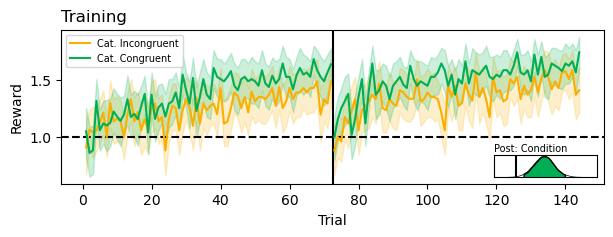

In [22]:
fig, ax = plt.subplots(figsize=(7, 2))

ax.axhline(1, color='black', linestyle='--')
ax.axvline(int(np.max(training_df['t'])/2) + 0.5, color='black')
for block in np.unique(training_df['block']):
    idx = training_df['block'] == block
    sns.lineplot(
        data = training_df.loc[idx],
        x = 't',
        y = 'reward',
        hue = 'sem_congruent',
        palette = CONDITION_COLORS,
        ax = ax
    )
handles = ax.get_legend_handles_labels()[0]
ax.legend(
    handles[:2],
    ['Cat. Incongruent', 'Cat. Congruent'],
    fontsize = 7,
    loc = 'upper left'
    )
ax.set_xlabel('Trial')
ax.set_ylabel('Reward')
ax.set_title('Training', loc='left')

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '20%',
    height = '30%',
    bbox_to_anchor =  (.05, -0.25, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_1.posterior['sem_congruent'].values.flatten(),
    label = 'Post: Condition',
    label_loc = 'left',
    chance_color = 'k',
    color = CONDITION_COLORS[1]
)


fig.savefig(
    f'{FIG_PATH}/training_curve.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )

## Average training reward by frequency and condition

In [23]:
model_df = training_df[['id', 'sem_congruent', 'freq', 'reward']]
model_2 = bmb.Model(
    "reward ~ freq*sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_2 = model_2.fit(
    random_seed = 2,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_2)

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id[300],-0.375,0.066,-0.502,-0.241,0.001,0.001,2028.0,3732.0,1.0
1|id[302],0.333,0.066,0.201,0.460,0.001,0.001,1999.0,3800.0,1.0
1|id[304],0.366,0.066,0.234,0.488,0.001,0.001,1944.0,3650.0,1.0
1|id[306],-0.350,0.066,-0.479,-0.222,0.001,0.001,1982.0,3792.0,1.0
1|id[307],0.255,0.066,0.124,0.379,0.001,0.001,1994.0,3438.0,1.0
...,...,...,...,...,...,...,...,...,...
Intercept,1.249,0.039,1.171,1.324,0.002,0.001,628.0,1342.0,1.0
freq,0.081,0.017,0.048,0.114,0.000,0.000,7768.0,5946.0,1.0
freq:sem_congruent,-0.063,0.024,-0.110,-0.016,0.000,0.000,7504.0,6908.0,1.0
sem_congruent,0.182,0.056,0.072,0.291,0.002,0.002,619.0,1260.0,1.0


Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


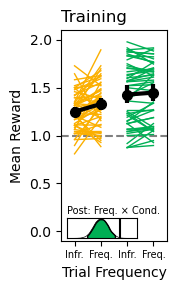

In [24]:
plot_by_condition_and_categorical(
    training_df,
    'freq',
    'reward',
    title = 'Training',
    x_label = 'Trial Frequency',
    y_label = 'Mean Reward',
    x_tick_labels = ['Infr.', 'Freq.'], 
    y_lim = [-.1, 2.1],
    summary_fname = f'{FIG_PATH}/stats/training-reward-by-frequency.pkl',
    fname = f'{FIG_PATH}/training-reward-by-frequency.pdf',
    posterior = fitted_2.posterior['freq:sem_congruent'],
    posterior_config = {
        'label': 'Post: Freq. × Cond.',
        'label_loc': 'left',
        'chance_color': 'black',
        'color': CONDITION_COLORS[1],
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48),
)

## Average test (old) reward by frequency and condition

In [25]:
model_df = test_df.loc[test_df['old'], ['id', 'sem_congruent', 'freq', 'reward']]
model_df = model_df.reset_index(drop=True)

model_3 = bmb.Model(
    "reward ~ freq*sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_3 = model_3.fit(
    random_seed = 3,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_3)[-5:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,1.024,0.041,0.943,1.103,0.001,0.000,3689.0,4900.0,1.0
freq,0.134,0.039,0.057,0.211,0.000,0.000,6403.0,5963.0,1.0
freq:sem_congruent,-0.027,0.056,-0.135,0.085,0.001,0.001,6114.0,5511.0,1.0
sem_congruent,0.279,0.057,0.171,0.392,0.001,0.001,3911.0,4981.0,1.0
sigma,0.688,0.010,0.668,0.707,0.000,0.000,9501.0,5635.0,1.0


Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


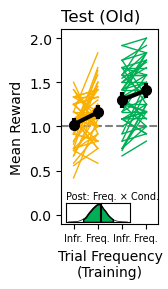

In [26]:
plot_by_condition_and_categorical(
    test_df.loc[test_df['old']],
    'freq',
    'reward',
    title = 'Test (Old)',
    x_label = 'Trial Frequency\n(Training)',
    y_label = 'Mean Reward',
    x_tick_labels = ['Infr.', 'Freq.'], 
    y_lim = [-.1, 2.1],
    summary_fname = f'{FIG_PATH}/stats/test-old-reward-by-frequency.pkl',
    fname = f'{FIG_PATH}/test-old-reward-by-frequency.pdf',
    posterior = fitted_3.posterior['freq:sem_congruent'],
    posterior_config = {
        'label': 'Post: Freq. × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48),
)

## Multi-step inference at test

In [27]:
idx = (test_df['n_steps'] == 2) & (test_df['n_transitions_to_target'] == 1)
model_df = test_df.loc[idx, ['id', 'sem_congruent','reward']]
model_df = model_df.reset_index(drop=True)

model_4 = bmb.Model(
    "reward ~ sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_4 = model_4.fit(
    random_seed = 4,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_4)[-5:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id[414],-0.049,0.045,-0.135,0.043,0.0,0.0,9222.0,5788.0,1.0
1|id_sigma,0.062,0.009,0.043,0.080,0.0,0.0,2943.0,4256.0,1.0
Intercept,0.501,0.012,0.476,0.525,0.0,0.0,3938.0,5044.0,1.0
sem_congruent,0.052,0.018,0.018,0.088,0.0,0.0,3915.0,4724.0,1.0
sigma,0.495,0.005,0.486,0.504,0.0,0.0,8051.0,6347.0,1.0


Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:863: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


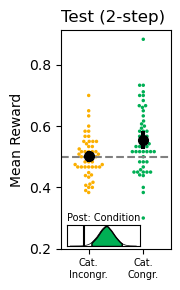

In [28]:
plot_by_categorical(
    model_df,
    'sem_congruent',
    'reward',
    title = 'Test (2-step)',
    x_label = None,
    y_label = 'Mean Reward',
    x_tick_labels = ['Cat.\nIncongr.', 'Cat.\nCongr.'], 
    y_lim = [0.2, None],
    chance = 0.5,
    summary_fname = f'{FIG_PATH}/stats/test-2-step.pkl',
    fname = f'{FIG_PATH}/test-2-step.pdf',
    posterior = fitted_4.posterior['sem_congruent'],
    posterior_config = {
        'label': 'Post: Condition',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48),
    palette = CONDITION_COLORS,
)

In [29]:
idx = (test_df['step'] == 1) & (test_df['n_transitions_to_target'] == 1)
model_df = test_df.loc[idx, ['id', 'sem_congruent', 'n_steps', 'reward']]
model_df = model_df.reset_index(drop=True)

model_5 = bmb.Model(
    "reward ~ n_steps*sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_5 = model_5.fit(
    random_seed = 5,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_5)[-5:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.603,0.028,0.546,0.658,0.000,0.0,5436.0,5959.0,1.0
n_steps,-0.050,0.015,-0.080,-0.020,0.000,0.0,6268.0,6212.0,1.0
n_steps:sem_congruent,-0.130,0.021,-0.171,-0.087,0.000,0.0,5468.0,5649.0,1.0
sem_congruent,0.311,0.040,0.232,0.388,0.001,0.0,4694.0,5255.0,1.0
sigma,0.484,0.004,0.477,0.491,0.000,0.0,14171.0,5509.0,1.0


Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


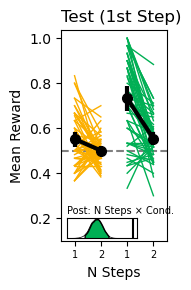

In [30]:
plot_by_condition_and_categorical(
    model_df,
    'n_steps',
    'reward',
    title = 'Test (1st Step)',
    x_label = 'N Steps',
    y_label = 'Mean Reward',
    x_tick_labels = [1, 2],
    summary_fname = f'{FIG_PATH}/stats/test-old-reward-by-n-steps.pkl',
    fname = f'{FIG_PATH}/test-old-reward-by-n-steps.pdf',
    posterior = fitted_5.posterior['n_steps:sem_congruent'],
    posterior_config = {
        'label': 'Post: N Steps × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48),
    chance = 0.5,
    y_lim = [0.1, None],
)

In [32]:
idx = (test_df['n_steps'] == 1) & (test_df['n_transitions_to_target'] == 1)
model_df = test_df.loc[idx, ['id', 'sem_congruent', 'step', 'reward']]
model_df = model_df.reset_index(drop=True)

model_6 = bmb.Model(
    "reward ~ step*sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_6 = model_6.fit(
    random_seed = 6,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_6)[-5:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.497,0.032,0.436,0.562,0.001,0.000,3767.0,4631.0,1.0
sem_congruent,0.275,0.045,0.188,0.368,0.001,0.001,3336.0,4386.0,1.0
sigma,0.454,0.004,0.446,0.462,0.000,0.000,17379.0,5685.0,1.0
step,0.055,0.017,0.021,0.087,0.000,0.000,7596.0,6251.0,1.0
step:sem_congruent,-0.094,0.023,-0.139,-0.047,0.000,0.000,6996.0,5455.0,1.0


Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


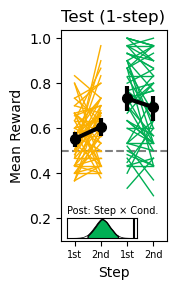

In [34]:
plot_by_condition_and_categorical(
    model_df,
    'step',
    'reward',
    title = 'Test (1-step)',
    x_label = 'Step',
    y_label = 'Mean Reward',
    x_tick_labels = ['1st', '2nd'],
    summary_fname = f'{FIG_PATH}/stats/test-old-reward-by-step.pkl',
    fname = f'{FIG_PATH}/test-old-reward-by-step.pdf',
    posterior = fitted_6.posterior['step:sem_congruent'],
    posterior_config = {
        'label': 'Post: Step × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48),
    chance = np.mean(test_df.loc[idx, 'n_transitions_to_target'])/2,
    y_lim = [0.1, None]
)

## Test performance by condition

In [21]:
model_df = test_df[['id', 'sem_congruent', 'reward']]
model_7a = bmb.Model(
    "reward ~ sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_7a = model_7a.fit(
    random_seed = 71,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_7a)[-7:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id[411],-0.011,0.041,-0.092,0.067,0.0,0.0,8614.0,5628.0,1.0
1|id[413],-0.005,0.041,-0.084,0.076,0.0,0.0,8793.0,5980.0,1.0
1|id[414],0.029,0.041,-0.049,0.112,0.0,0.0,8566.0,5907.0,1.0
1|id_sigma,0.086,0.008,0.072,0.101,0.0,0.0,2571.0,4530.0,1.0
Intercept,0.523,0.014,0.497,0.550,0.0,0.0,2682.0,3912.0,1.0
sem_congruent,0.100,0.019,0.063,0.139,0.0,0.0,2591.0,3525.0,1.0
sigma,0.589,0.003,0.582,0.595,0.0,0.0,8643.0,5110.0,1.0


Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_92637/294567920.py:863: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


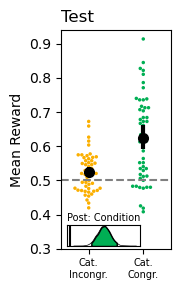

In [22]:
plot_by_categorical(
    model_df,
    'sem_congruent',
    'reward',
    title = 'Test',
    x_label = None,
    y_label = 'Mean Reward',
    x_tick_labels = ['Cat.\nIncongr.', 'Cat.\nCongr.'], 
    y_lim = [.3, None],
    chance = .5,
    summary_fname = f'{FIG_PATH}/stats/test-reward-by-condition.pkl',
    fname = f'{FIG_PATH}/test-reward-by-condition.pdf',
    posterior = fitted_7a.posterior['sem_congruent'],
    posterior_config = {
        'label': 'Post: Condition',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48),
    palette = CONDITION_COLORS
)

## Test performance by condition and target/options novelty

In [35]:
idx = (test_df['n_transitions_to_target'] == 1) 
model_df = test_df.loc[idx, [
    'id',
    'sem_congruent',
    'novel_target',
    'novel_options',
    'reward'
]]
model_df = model_df.reset_index(drop=True)

model_7 = bmb.Model(
    "reward ~ novel_target*sem_congruent + novel_options*sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_7 = model_7.fit(
    random_seed = 7,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_7)[-7:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.550,0.022,0.509,0.595,0.0,0.0,4628.0,5148.0,1.0
novel_options,-0.005,0.015,-0.034,0.024,0.0,0.0,8756.0,6225.0,1.0
novel_options:sem_congruent,0.014,0.021,-0.028,0.056,0.0,0.0,8004.0,6457.0,1.0
novel_target,-0.010,0.015,-0.038,0.020,0.0,0.0,7829.0,5908.0,1.0
novel_target:sem_congruent,0.018,0.021,-0.024,0.059,0.0,0.0,6988.0,6108.0,1.0
sem_congruent,0.071,0.032,0.011,0.135,0.0,0.0,4268.0,4616.0,1.0
sigma,0.483,0.003,0.476,0.489,0.0,0.0,20058.0,5061.0,1.0


Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


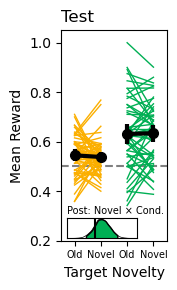

In [37]:
plot_by_condition_and_categorical(
    test_df.loc[test_df['n_transitions_to_target'] == 1],
    'novel_target',
    'reward',
    title = 'Test',
    x_label = 'Target Novelty',
    y_label = 'Mean Reward',
    x_tick_labels = ['Old', 'Novel'], 
    y_lim = [0.2, 1.05],
    chance = .5,
    summary_fname = f'{FIG_PATH}/stats/test-reward-by-novel-target.pkl',
    fname = f'{FIG_PATH}/test-reward-by-novel-target.pdf',
    posterior = fitted_7.posterior['novel_target:sem_congruent'],
    posterior_config = {
        'label': 'Post: Novel × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48)
)

Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


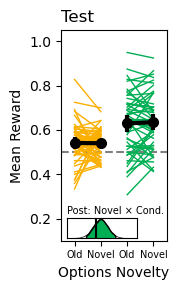

In [38]:
plot_by_condition_and_categorical(
    test_df.loc[test_df['n_transitions_to_target'] == 1],
    'novel_options',
    'reward',
    title = 'Test',
    x_label = 'Options Novelty',
    y_label = 'Mean Reward',
    x_tick_labels = ['Old', 'Novel'], 
    y_lim = [0.1, 1.05],
    chance = .5,
    summary_fname = f'{FIG_PATH}/stats/test-reward-by-novel-options.pkl',
    fname = f'{FIG_PATH}/test-reward-by-novel-options.pdf',
    posterior = fitted_7.posterior['novel_options:sem_congruent'],
    posterior_config = {
        'label': 'Post: Novel × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48)
)

In [39]:
idx = (test_df['n_transitions_to_target'] == 1)  & (test_df['n_steps'] == 1)
model_df = test_df.loc[idx, [
    'id',
    'sem_congruent',
    'novel_target',
    'novel_options',
    'reward'
]]
model_df = model_df.reset_index(drop=True)

model_8 = bmb.Model(
    "reward ~ novel_target*sem_congruent + novel_options*sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_8 = model_8.fit(
    random_seed = 8
)
az.summary(fitted_8)[-7:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.584,0.031,0.526,0.645,0.001,0.000,1946.0,2664.0,1.0
novel_options,-0.003,0.020,-0.042,0.036,0.000,0.000,3782.0,3140.0,1.0
novel_options:sem_congruent,-0.001,0.028,-0.055,0.054,0.000,0.000,3464.0,2979.0,1.0
novel_target,-0.003,0.021,-0.042,0.038,0.000,0.000,4108.0,3201.0,1.0
novel_target:sem_congruent,-0.003,0.028,-0.057,0.052,0.000,0.000,3900.0,3439.0,1.0
sem_congruent,0.135,0.043,0.053,0.220,0.001,0.001,1621.0,2389.0,1.0
sigma,0.455,0.004,0.447,0.463,0.000,0.000,9827.0,2790.0,1.0


Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


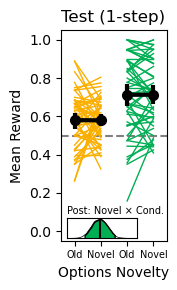

In [40]:
plot_by_condition_and_categorical(
    test_df.loc[(test_df['n_transitions_to_target'] == 1) & (test_df['n_steps'] == 1)],
    'novel_options',
    'reward',
    title = 'Test (1-step)',
    x_label = 'Options Novelty',
    y_label = 'Mean Reward',
    x_tick_labels = ['Old', 'Novel'], 
    y_lim = [-.05, 1.05],
    chance = .5,
    summary_fname = f'{FIG_PATH}/stats/test-reward-by-novel-options-1step.pkl',
    fname = f'{FIG_PATH}/test-reward-by-novel-options-1step.pdf',
    posterior = fitted_8.posterior['novel_options:sem_congruent'],
    posterior_config = {
        'label': 'Post: Novel × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48)
)

Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


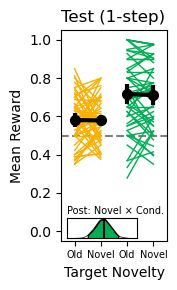

In [41]:
plot_by_condition_and_categorical(
    test_df.loc[(test_df['n_transitions_to_target'] == 1) & (test_df['n_steps'] == 1)],
    'novel_target',
    'reward',
    title = 'Test (1-step)',
    x_label = 'Target Novelty',
    y_label = 'Mean Reward',
    x_tick_labels = ['Old', 'Novel'], 
    y_lim = [-.05, 1.05],
    chance = .5,
    summary_fname = f'{FIG_PATH}/stats/test-reward-by-novel-target-1step.pkl',
    fname = f'{FIG_PATH}/test-reward-by-novel-target-1step.pdf',
    posterior = fitted_8.posterior['novel_target:sem_congruent'],
    posterior_config = {
        'label': 'Post: Novel × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48)
)

In [42]:
idx = (test_df['n_transitions_to_target'] == 1)  & (test_df['n_steps'] == 2)
model_df = test_df.loc[idx, [
    'id',
    'sem_congruent',
    'novel_target',
    'novel_options',
    'reward'
]]
model_df = model_df.reset_index(drop=True)

model_9 = bmb.Model(
    "reward ~ novel_target*sem_congruent + novel_options*sem_congruent + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_9 = model_9.fit(
    random_seed = 9
)
az.summary(fitted_9)[-7:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.524,0.028,0.468,0.580,0.001,0.000,2614.0,2741.0,1.0
novel_options,-0.013,0.022,-0.055,0.030,0.000,0.000,3883.0,3514.0,1.0
novel_options:sem_congruent,0.030,0.030,-0.032,0.087,0.001,0.000,3557.0,2923.0,1.0
novel_target,-0.022,0.022,-0.063,0.023,0.000,0.000,3268.0,3072.0,1.0
novel_target:sem_congruent,0.040,0.031,-0.021,0.100,0.001,0.000,3232.0,3179.0,1.0
sem_congruent,0.005,0.040,-0.071,0.083,0.001,0.001,2617.0,2494.0,1.0
sigma,0.495,0.005,0.487,0.504,0.000,0.000,8091.0,2412.0,1.0


Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:737: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


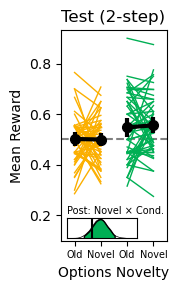

In [43]:
plot_by_condition_and_categorical(
    test_df.loc[(test_df['n_transitions_to_target'] == 1) & (test_df['n_steps'] == 2)],
    'novel_options',
    'reward',
    title = 'Test (2-step)',
    x_label = 'Options Novelty',
    y_label = 'Mean Reward',
    x_tick_labels = ['Old', 'Novel'], 
    y_lim = [0.1, None],
    chance = .5,
    summary_fname = f'{FIG_PATH}/stats/test-reward-by-novel-options-2step.pkl',
    fname = f'{FIG_PATH}/test-reward-by-novel-options-2step.pdf',
    posterior = fitted_9.posterior['novel_options:sem_congruent'],
    posterior_config = {
        'label': 'Post: Novel × Cond.',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48)
)

## Composition spurious predictiveness by condition

In [44]:
idx = (test_df['spurious_trial'] == 1)
model_df = test_df.loc[idx, ['id', 'sem_congruent', 'comp_spur_pred']]
model_10 = bmb.Model(
    'comp_spur_pred ~ sem_congruent + (1|id)',
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_10 = model_10.fit(
    random_seed = 10,
    tune = 2000,
    draws = 2000
)
az.summary(fitted_10)[-3:]

Output()

There were 7 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.953,0.027,0.898,1.005,0.0,0.0,9034.0,4089.0,1.0
sem_congruent,-0.018,0.038,-0.090,0.059,0.0,0.0,9640.0,4592.0,1.0
sigma,0.713,0.013,0.686,0.738,0.0,0.0,9386.0,4929.0,1.0


In [19]:
model_10b = bmb.Model(
    'comp_spur_pred ~ (1|id)',
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_10b = model_10b.fit(
    random_seed = 102,
    tune = 2000,
    draws = 2000
)
az.summary(fitted_10b)[-3:]

Output()

There were 4 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id_sigma,0.035,0.025,0.000,0.084,0.0,0.0,3320.0,3858.0,1.0
Intercept,0.944,0.019,0.908,0.981,0.0,0.0,11528.0,5752.0,1.0
sigma,0.712,0.013,0.687,0.738,0.0,0.0,11862.0,4674.0,1.0


Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:863: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


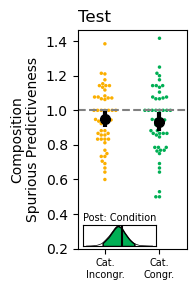

In [45]:
plot_by_categorical(
    model_df,
    'sem_congruent',
    'comp_spur_pred',
    title = 'Test',
    x_label = None,
    y_label = 'Composition\nSpurious Predictiveness',
    x_tick_labels = ['Cat.\nIncongr.', 'Cat.\nCongr.'], 
    y_lim = [0.2, None],
    chance = 1,
    summary_fname = f'{FIG_PATH}/stats/comp-spur-pred-by-condition.pkl',
    fname = f'{FIG_PATH}/comp-spur-pred-by-condition.pdf',
    posterior = fitted_10.posterior['sem_congruent'],
    posterior_config = {
        'label': 'Post: Condition',
        'label_loc': 'left',
        'chance_color' : 'k',
        'color': CONDITION_COLORS[1]
    },
    bbox_to_anchor = (-.17, -.34, .95, 0.48),
    palette = CONDITION_COLORS
)

# Model Fits


## Group-level AIC comparison

In [46]:
plot_df = model_fits_df[['model_label', 'aic']]
plot_df = plot_df.groupby(['model_label'])
plot_df = plot_df.sum()
plot_df = plot_df.sort_values('aic', ascending=True)
plot_df

,aic
model_label,
sf-ff-bias-nonlin,79956.010248
sf-ff-nonlin,80191.664358
sf-ff-bias-decay,80400.454366
sf-ff-bias-l1reg,80418.737364
mb-ff-bias,80705.397844
sf-ff-bias,80762.989046
sf-ff-decay,81148.217846
mb-ff,81249.104441
sf-ff,81279.129398


## Fits by models with vs without bias

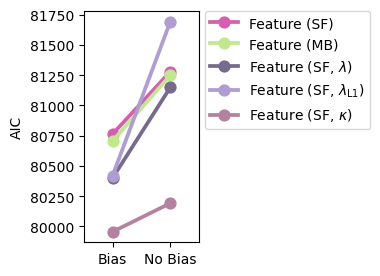

In [50]:
# Get model_labels with 'ff' in 
idx = model_fits_df['model_label'].str.contains('ff')
plot_df = model_fits_df.loc[idx][['model_label', 'aic']]
plot_df = plot_df.groupby(['model_label'])
plot_df = plot_df.sum()
plot_df = plot_df.sort_values('aic', ascending=True)
plot_df = plot_df.reset_index()

def identify_bias_label(label):
    if 'bias' in label:
        return 'Bias'
    else:
        return 'No Bias'

plot_df['bias'] = plot_df['model_label'].apply(identify_bias_label)

# strip "bias" from model label
plot_df['model_label_class'] = plot_df['model_label'].str.replace(
    '-bias', '', regex=False
    )

fig, ax = plt.subplots(figsize=(2, 3))

sns.pointplot(
    data = plot_df,
    x = 'bias',
    y = 'aic',
    hue = 'model_label_class',
    hue_order = FF_MODEL_LABELS.keys(),
    palette = FF_MODEL_COLORS,
    ax = ax
)

handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, FF_MODEL_LABELS.values(), loc=(1.05, .49))
ax.set_xlabel(None)
ax.set_ylabel('AIC')
ax.set_box_aspect(2)

fig.savefig(
    f'{FIG_PATH}/ff-model-fits-by-bias.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )


## Plot proportion of best fits per model

In [51]:
plot_df = best_fits[['model_label', 'best_fit']]
plot_df = plot_df.groupby(['model_label'])
plot_df = plot_df.sum()
plot_df['best_fit'] = plot_df['best_fit']/np.sum(plot_df['best_fit'])
plot_df = plot_df.sort_values('best_fit', ascending=False)
plot_df = plot_df.reset_index()
plot_df

,model_label,best_fit
0,mb-ss,0.166667
1,sf-ff-nonlin,0.166667
2,sf-ff-bias-l1reg,0.147059
3,sf-ff-bias-nonlin,0.098039
4,null,0.078431
5,mb-ff,0.068627
6,sf-ss,0.058824
7,sf-ff,0.049020
8,sf-ss-sampler,0.049020
9,mb-ff-bias,0.039216


## Relative likelihoods for best fitting feature-based vs conjunctive vs null

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/3929493379.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


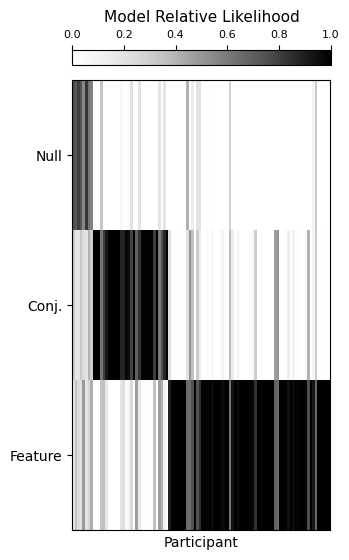

In [53]:
model_fits_df['model_class_2'] = model_fits_df['model_class'].replace({
    'null': 'null',
    'ss': 'ss',
    'ss-sampler': 'ss',
    'ff': 'ff'
})


aics = model_fits_df[['id', 'model_class_2', 'aic']]
aics = aics.groupby(['id', 'model_class_2']).min()
aics = aics.reset_index()
aics = pd.pivot(
    aics,
    index = 'id',
    columns = 'model_class_2',
    values = 'aic'
)
aics = aics.reset_index()

# Re-order columns
aics = aics[['id', 'null', 'ss', 'ff']]

# Compute model relative likelihoods from raw AICs
raw_aics = np.array(aics.iloc[:, 1:])
delta_aic = raw_aics - np.min(raw_aics, axis=1).reshape(-1, 1)
numerator = np.exp(-delta_aic/2)
aic_w = numerator/np.sum(numerator, axis=1).reshape(-1, 1)

# Sort the rows based on the maximum value index
max_indices = np.argmax(aic_w, axis=1)
sorted_indices = np.argsort(max_indices)
aic_w = aic_w[sorted_indices]
aic_w = aic_w.T

# Covert to data frame
relative_likelihoods = pd.DataFrame(
    aic_w.T,
    columns = aics.columns[1:]
)
relative_likelihoods
relative_likelihoods['id'] = np.array(aics['id'])[sorted_indices]

# Create the heatmap with alpha values based on cell value
fig, ax = plt.subplots(figsize=(3.5, 5))
for i, model_label in enumerate(aics.columns[1:]):
    for j in range(aic_w.shape[1]):
        ax.add_patch(
            plt.Rectangle(
                (j, 2 - i), 1, 1,
                color = 'k',
                alpha = aic_w[i, j],
                linewidth = 0
                )
            )

# Remove axes and ticks for clarity
ax.set_xticks([])
#ax.set_yticks([.5, 1.5, 2.5, 3.5], labels=MODEL_LABELS[::-1])
ax.set_yticks([.5, 1.5, 2.5])
ax.set_yticklabels([
    'Feature',
    'Conj.',
    'Null'
])

ax.set_xlim(0, aic_w.shape[1])
ax.set_ylim(0, aic_w.shape[0])
ax.set_xlabel('Participant')
#ax.set_title('Model Relative Likelihoods', loc='left', fontsize=11)


from matplotlib.cm import Greys, ScalarMappable
from matplotlib.colors import Normalize

# Create a ScalarMappable for the alpha scale (0 to 1)
sm = ScalarMappable(cmap=Greys, norm=Normalize(vmin=0, vmax=1))
sm.set_array([])  

# Add horizontal colorbar below the x-axis
cbar_ax = fig.add_axes([0.22, 1, 0.74, 0.03])  
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
#cbar.set_label('Relative Likelihood', fontsize=9)

cbar.ax.set_title('Model Relative Likelihood', fontsize=11, pad=6)
cbar.ax.tick_params(labelsize=8)
cbar.ax.xaxis.set_ticks_position('top') 

fig.tight_layout()

plt.savefig(
    f'{FIG_PATH}/model-relative-likelihoods.pdf',
    bbox_inches = 'tight',
    dpi = 300 
    )


In [54]:
best_relative_likelihoods = pd.melt(
    relative_likelihoods,
    'id',
    value_name = 'rl'
)

best_relative_likelihoods = pd.merge(
    model_fits_df[['id', 'model_class_2', 'best_fit']], 
    best_relative_likelihoods
)
idx = best_relative_likelihoods['best_fit'] == 1
best_relative_likelihoods = best_relative_likelihoods.loc[idx]

best_relative_likelihoods = best_relative_likelihoods[['model_class_2', 'rl']].groupby('model_class_2')
mean_relative_likelihoods = np.round(best_relative_likelihoods.mean(), 4)
std_relative_likelihoods = np.round(best_relative_likelihoods.std(), 4)

print('Means')
print(mean_relative_likelihoods)

print('\n\nSDs')
print(std_relative_likelihoods)

Means
                   rl
model_class_2        
ff             0.9303
null           0.6347
ss             0.8932


SDs
                   rl
model_class_2        
ff             0.1343
null           0.1200
ss             0.1472


/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_28567/1784156100.py:126: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


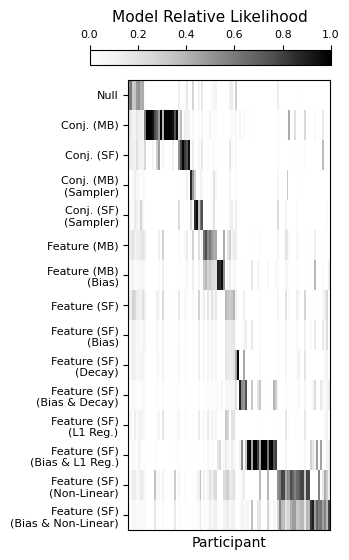

In [ ]:
aics = model_fits_df[['id', 'model_label', 'aic']]
aics = pd.pivot(
    aics,
    index = 'id',
    columns = 'model_label',
    values = 'aic'
)
aics = aics.reset_index()

aics = aics.fillna(0)

# Re-order columns
aics = aics[[
    'id',
    'null',
    'mb-ss',
    'sf-ss',
    'mb-ss-sampler',
    'sf-ss-sampler',
    'mb-ff',
    'mb-ff-bias',
    'sf-ff',
    'sf-ff-bias',
    'sf-ff-decay',
    'sf-ff-bias-decay',
    'sf-ff-l1reg',
    'sf-ff-bias-l1reg',
    'sf-ff-nonlin',
    'sf-ff-bias-nonlin'
    ]]

# Compute model relative likelihoods from raw AICs
raw_aics = np.array(aics.iloc[:, 1:])
delta_aic = raw_aics - np.min(raw_aics, axis=1).reshape(-1, 1)
numerator = np.exp(-delta_aic/2)
aic_w = numerator/np.sum(numerator, axis=1).reshape(-1, 1)

# Sort the rows based on the maximum value index
max_indices = np.argmax(aic_w, axis=1)
sorted_indices = np.argsort(max_indices)
aic_w = aic_w[sorted_indices]
aic_w = aic_w.T

# Covert to data frame
relative_likelihoods = pd.DataFrame(
    aic_w.T,
    columns = aics.columns[1:]
)
relative_likelihoods
relative_likelihoods['id'] = np.array(aics['id'])[sorted_indices]

# Create the heatmap with alpha values based on cell value
fig, ax = plt.subplots(figsize=(3.5, 5))
for i, model_label in enumerate(aics.columns[1:]):
    for j in range(aic_w.shape[1]):
        ax.add_patch(
            plt.Rectangle(
                (j, np.shape(aics)[1] - 2 - i), 1, 1,
                color = 'k',
                alpha = aic_w[i, j],
                linewidth = 0
                )
            )

# Remove axes and ticks for clarity
ax.set_xticks([])
ax.set_yticks(np.arange(np.shape(aics)[1] - 1) + 0.5)#, labels=MODEL_LABELS[::-1])
ax.set_yticklabels([
    'Feature (SF)\n(Bias & Non-Linear)',
    'Feature (SF)\n(Non-Linear)',
    'Feature (SF)\n(Bias & L1 Reg.)',
    'Feature (SF)\n(L1 Reg.)',
    'Feature (SF)\n(Bias & Decay)',
    'Feature (SF)\n(Decay)',
    'Feature (SF)\n(Bias)',
    'Feature (SF)',
    'Feature (MB)\n(Bias)',
    'Feature (MB)',
    'Conj. (SF)\n(Sampler)',
    'Conj. (MB)\n(Sampler)',
    'Conj. (SF)',
    'Conj. (MB)',
    'Null'
], fontsize=8)

ax.set_xlim(0, aic_w.shape[1])
ax.set_ylim(0, aic_w.shape[0])
ax.set_xlabel('Participant')

from matplotlib.cm import Greys, ScalarMappable
from matplotlib.colors import Normalize

# Create a ScalarMappable for the alpha scale (0 to 1)
sm = ScalarMappable(cmap=Greys, norm=Normalize(vmin=0, vmax=1))
sm.set_array([])  

# Add horizontal colorbar below the x-axis
cbar_ax = fig.add_axes([0.27, 1, 0.69, 0.03])  
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
#cbar.set_label('Relative Likelihood', fontsize=9)

cbar.ax.set_title('Model Relative Likelihood', fontsize=11, pad=6)
cbar.ax.tick_params(labelsize=8)
cbar.ax.xaxis.set_ticks_position('top') 

fig.tight_layout()


In [53]:
best_relative_likelihoods = pd.melt(
    relative_likelihoods,
    'id',
    var_name = 'model_label',
    value_name = 'rl'
)

best_relative_likelihoods = pd.merge(
    model_fits_df[['id', 'model_label', 'best_fit']], 
    best_relative_likelihoods
)
idx = best_relative_likelihoods['best_fit'] == 1
best_relative_likelihoods = best_relative_likelihoods.loc[idx]

best_relative_likelihoods = best_relative_likelihoods[['model_label', 'rl']].groupby('model_label')
mean_relative_likelihoods = np.round(best_relative_likelihoods.mean(), 4)
std_relative_likelihoods = np.round(best_relative_likelihoods.std(), 4)

print('Means')
print(mean_relative_likelihoods)

print('\n\nSDs')
print(std_relative_likelihoods)

Means
                       rl
model_label              
mb-ff              0.4729
mb-ff-bias         0.7768
mb-ss              0.8218
mb-ss-sampler      0.6229
null               0.3594
sf-ff              0.2380
sf-ff-bias-decay   0.6053
sf-ff-bias-l1reg   0.8203
sf-ff-bias-nonlin  0.5569
sf-ff-decay        0.6620
sf-ff-nonlin       0.5765
sf-ss              0.7550
sf-ss-sampler      0.6475


SDs
                       rl
model_label              
mb-ff              0.1321
mb-ff-bias         0.2203
mb-ss              0.2436
mb-ss-sampler      0.2981
null               0.1126
sf-ff              0.0389
sf-ff-bias-decay   0.2145
sf-ff-bias-l1reg   0.2439
sf-ff-bias-nonlin  0.1931
sf-ff-decay        0.4508
sf-ff-nonlin       0.1561
sf-ss              0.2023
sf-ss-sampler      0.2751


### Summarize parameter fits

#### Means

In [110]:
best_fits['inference_power'] = best_fits['inference_power'].replace(-999, np.nan)
best_fits['inference_power'] = best_fits['inference_power'].replace(0, 1e-10)
best_fits['sampler_specificity'] = best_fits['sampler_specificity'].replace(-999, np.nan)

param_fits = best_fits[[
    'model_label',
    'alpha',
    'beta',
    'bias_magnitude',
    'lmbd',
    'lmbd_l1',
    'inference_power',
    'sampler_feature_weight',
    'sampler_specificity'
]]
param_fits = param_fits.replace(-999, np.nan)
param_fits['beta_trans'] = np.log(param_fits['beta'])
param_fits['inference_power_trans'] = np.log(param_fits['inference_power'])
param_fits['sampler_specificity_trans'] = np.log(param_fits['sampler_specificity'])
param_fits = param_fits.groupby('model_label')
param_fits = param_fits.mean()
param_fits = np.round(param_fits, 3)
param_fits

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,alpha,beta,bias_magnitude,lmbd,lmbd_l1,inference_power,sampler_feature_weight,sampler_specificity,beta_trans,inference_power_trans,sampler_specificity_trans
model_label,,,,,,,,,,,
mb-ff,0.153,3.479,0.000,NaN,NaN,NaN,NaN,NaN,0.548,NaN,NaN
mb-ff-bias,0.011,123.251,0.819,NaN,NaN,NaN,NaN,NaN,3.889,NaN,NaN
mb-ss,0.653,1.548,0.000,NaN,NaN,NaN,NaN,NaN,0.377,NaN,NaN
mb-ss-sampler,0.050,171.950,0.000,NaN,NaN,NaN,0.119,4.261,3.315,NaN,1.009
null,-1.000,-1.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sf-ff,0.164,6.389,0.000,NaN,NaN,NaN,NaN,NaN,1.187,NaN,NaN
sf-ff-bias-decay,0.401,8.097,0.677,0.862,NaN,NaN,NaN,NaN,2.009,NaN,NaN
sf-ff-bias-l1reg,0.604,6.778,0.828,NaN,0.273,NaN,NaN,NaN,1.863,NaN,NaN
sf-ff-bias-nonlin,0.481,814.918,0.766,NaN,NaN,56.129,NaN,NaN,2.171,0.448,NaN


#### Standard Deviations

In [17]:
best_fits['inference_power'] = best_fits['inference_power'].replace(-999, np.nan)
best_fits['inference_power'] = best_fits['inference_power'].replace(0, 1e-10)
best_fits['sampler_specificity'] = best_fits['sampler_specificity'].replace(-999, np.nan)


param_fits = best_fits[[
    'model_label',
    'alpha',
    'beta',
    'bias_magnitude',
    'lmbd',
    'lmbd_l1',
    'inference_power',
    'sampler_feature_weight',
    'sampler_specificity'
]]
param_fits = param_fits.replace(-999, np.nan)
param_fits['beta_trans'] = np.log(param_fits['beta'])
param_fits['inference_power_trans'] = np.log(param_fits['inference_power'])
param_fits['sampler_specificity_trans'] = np.log(param_fits['sampler_specificity'])
param_fits = param_fits.groupby('model_label')
param_fits = param_fits.std()
param_fits = np.round(param_fits, 3)
param_fits

/Users/euanprentis/opt/anaconda3/envs/bambi/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,alpha,beta,bias_magnitude,lmbd,lmbd_l1,inference_power,sampler_feature_weight,sampler_specificity,beta_trans,inference_power_trans,sampler_specificity_trans
model_label,,,,,,,,,,,
mb-ff,0.174,3.984,0.000,NaN,NaN,NaN,NaN,NaN,1.344,NaN,NaN
mb-ff-bias,0.009,195.952,0.211,NaN,NaN,NaN,NaN,NaN,1.469,NaN,NaN
mb-ss,0.281,0.514,0.000,NaN,NaN,NaN,NaN,NaN,0.376,NaN,NaN
mb-ss-sampler,0.070,240.041,0.000,NaN,NaN,NaN,0.151,4.611,3.563,NaN,1.427
null,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sf-ff,0.179,8.354,0.000,NaN,NaN,NaN,NaN,NaN,1.272,NaN,NaN
sf-ff-bias-decay,0.246,3.132,0.257,0.162,NaN,NaN,NaN,NaN,0.515,NaN,NaN
sf-ff-bias-l1reg,0.229,1.932,0.239,NaN,0.054,NaN,NaN,NaN,0.358,NaN,NaN
sf-ff-bias-nonlin,0.340,2562.512,0.261,NaN,NaN,167.590,NaN,NaN,2.444,2.789,NaN


### Are participants' choices best explained by the feature-based model?

In [65]:
best_fits['model_rep'] = best_fits['model_class'].replace({'ss-sampler': 'ss'})

best_fits['model_rep'] = pd.Categorical(
    best_fits['model_rep'], 
    categories = ['ff', 'null', 'ss'], 
    ordered = True
)

best_fits.groupby('model_rep')['model_rep'].count()/len(best_fits)

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_28567/847681428.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  best_fits.groupby('model_rep')['model_rep'].count()/len(best_fits)


model_rep
ff      0.627451
null    0.078431
ss      0.294118
Name: model_rep, dtype: float64

In [66]:
model_11 = bmb.Model(
    'model_rep ~ 1',
    best_fits,
    family = 'multinomial'
)
fitted_11 = model_11.fit(
    random_seed = 11,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_11)

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept[1],-2.091,0.376,-2.831,-1.359,0.005,0.003,6581.0,5225.0,1.0
Intercept[2],-0.757,0.220,-1.195,-0.347,0.003,0.002,7194.0,5943.0,1.0


## Bias Magnitude fits 

### Is fit bias magnitude higher in the semantic congruent condition?

In [54]:
idx = best_fits['ff_fit'] == 1
model_df = best_fits.loc[idx]

idx = model_df['bias_magnitude'] == 1
model_df.loc[idx, 'bias_magnitude'] = .9999
idx = model_df['bias_magnitude'] == 0
model_df.loc[idx, 'bias_magnitude'] = .0001

model_14 = bmb.Model(
    "bias_magnitude ~ sem_congruent",
    model_df,
    family = 'beta',
    link = 'logit'
)
fitted_14 = model_14.fit(
    random_seed = 14,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_14)

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-1.037,0.272,-1.565,-0.503,0.003,0.002,9561.0,6198.0,1.0
kappa,0.379,0.052,0.280,0.482,0.001,0.000,9525.0,6573.0,1.0
sem_congruent,1.166,0.361,0.505,1.920,0.004,0.003,9963.0,6373.0,1.0


### Get mean and HDI of posterior predictions

In [73]:
# Generate means and HDIs of each data group
posterior_summaries = []
for condition in [0, 1]:
    idx = model_df['sem_congruent'] == condition
    model = bmb.Model('bias_magnitude ~ 1', model_df.loc[idx])
    fitted = model.fit(random_seed=23232)
    post_values = az.summary(fitted)
    post_values = post_values[['mean', 'hdi_2.5%', 'hdi_97.5%']].values[0]
    posterior_summaries.append(post_values)
posterior_summaries = np.array(posterior_summaries)

Output()

Output()

### Plot fit segmentation by condition

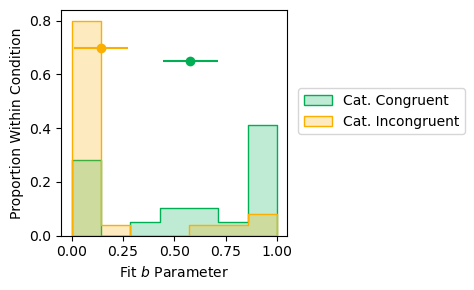

In [74]:
fig, ax = plt.subplots(figsize=(5, 3))

# Histogram of bias parameter fits
sns.histplot(
    data = model_df,
    x = 'bias_magnitude',
    hue = 'sem_congruent',
    palette = CONDITION_COLORS,
    stat = 'probability',
    common_norm = False,
    element = 'step',
    ax = ax
)

# Plot means and 95% HDIs
ax.hlines(.7, *posterior_summaries[0, 1:], color=CONDITION_COLORS[0])
ax.plot(posterior_summaries[0, 0], .7, 'o', color=CONDITION_COLORS[0])
ax.hlines(.65, *posterior_summaries[1, 1:], color=CONDITION_COLORS[1])
ax.plot(posterior_summaries[1, 0], .65, 'o', color=CONDITION_COLORS[1])

# Format
ax.legend(['Cat. Congruent', 'Cat. Incongruent'], loc=(1.05, .45))
ax.set_xlabel('Fit Bias Magnitude Parameter')
ax.set_xlabel(r'Fit $\it{b}$ Parameter')
ax.set_ylabel('Proportion Within Condition')
set_axis_ratio(ax)
fig.tight_layout()

plt.savefig(f'{FIG_PATH}/bias-magnitude-by-condition.pdf')

# Training Transition Influence Analysis

In [75]:
model_15 = bmb.Model(
    "coef ~ sem_congruent*transition + (1|action) + (1|id)",
    trans_influence_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_15 = model_15.fit(
    random_seed = 15,
    tune = 4000,
    draws = 2000,
    target_accept = .95
)
az.summary(fitted_15)

Output()

There were 56 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.014,0.139,-0.283,0.329,0.004,0.004,1945.0,1265.0,1.0
1|action[2],-0.002,0.137,-0.320,0.283,0.004,0.004,1927.0,1285.0,1.0
1|action[3],-0.001,0.136,-0.306,0.301,0.004,0.004,2101.0,1195.0,1.0
1|action_sigma,0.164,0.244,0.000,0.623,0.007,0.005,1891.0,1427.0,1.0
1|id[300],-0.725,0.438,-1.567,0.126,0.005,0.004,7728.0,4355.0,1.0
...,...,...,...,...,...,...,...,...,...
Intercept,0.584,0.196,0.185,0.963,0.005,0.003,1737.0,1476.0,1.0
sem_congruent,-0.555,0.215,-0.980,-0.136,0.004,0.003,2314.0,3737.0,1.0
sem_congruent:transition[causal],1.847,0.193,1.464,2.225,0.003,0.002,4591.0,5068.0,1.0
sigma,1.205,0.037,1.133,1.278,0.000,0.000,6913.0,6262.0,1.0


### Get posterior predictions from model

In [76]:
# Generate means and HDIs of each data group
posterior_summaries = []
for condition in [0, 1]:
    for transition in ['spurious', 'causal']:
        idx = (
            (mean_trans_influence_df['sem_congruent'] == condition) &
            (mean_trans_influence_df['transition'] == transition)
        )
        model = bmb.Model('coef ~ 1', mean_trans_influence_df.loc[idx])
        fitted = model.fit(random_seed=4793)
        post_values = az.summary(fitted)
        post_values = post_values[['mean', 'hdi_2.5%', 'hdi_97.5%']].values[0]
        posterior_summaries.append(post_values)
posterior_summaries = np.array(posterior_summaries)

Output()

Output()

Output()

Output()

### Plot transition influence by condition 

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/1663413065.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


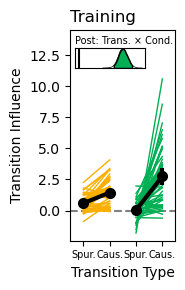

In [77]:
# Each participants average reward on old and novel target trials
plot_df = mean_trans_influence_df[['id', 'sem_congruent', 'transition', 'coef']]
plot_df['transition'] = plot_df['transition'].map({
    'spurious': 0,
    'causal': 1
}).astype(int)
plot_df['group'] = plot_df['sem_congruent']*2 + plot_df['transition']

fig, ax = plt.subplots(figsize=(2, 3))

# Plot data
ax.axhline(0, c='.5', linestyle='--')
sns.lineplot(
    data = plot_df,
    x = 'group',
    y = 'coef',
    hue = 'id',
    palette = condition_id_palette,
    linewidth = 1,
    ax = ax
)

for i, hdi in enumerate(posterior_summaries[:, 1:]):
    ax.vlines(np.unique(plot_df['group'])[i], *hdi, color='black', linewidth=3)
ax.plot(
    np.unique(plot_df['group'])[:2],
    posterior_summaries[:2, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)
ax.plot(
    np.unique(plot_df['group'])[2:],
    posterior_summaries[2:, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)

# Format
ax.set_xlim([np.min(np.unique(plot_df['group'])) - .5, np.max(np.unique(plot_df['group'])) + .5])
ax.get_legend().remove()
ax.set_xticks(np.unique(plot_df['group']))
ax.set_xticklabels(['Spur.', 'Caus.']*2, fontsize=7)

ax.set_xlabel('Transition Type')
ax.set_ylabel('Transition Influence')
ax.set_ylim([None, 14.5])
ax.set_title('Training', loc='left')
set_axis_ratio(ax, 2)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '70%',
    height = '20%',
    bbox_to_anchor =  (-.17, 0.47, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_15.posterior['sem_congruent:transition'].values.flatten(),
    label = 'Post: Trans. × Cond.',
    label_loc = 'left',
    chance_color = 'black',
    color = CONDITION_COLORS[1],
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/transition-influence-by-condition.pdf')

### Run pairwise comparisons models

#### Comparing transition type congruent condition

In [78]:
idx = trans_influence_df['sem_congruent'] == 0
model_15a = bmb.Model(
    "coef ~ transition + (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_15a = model_15a.fit(
    random_seed = 151, 
    target_accept = .9,
    tune = 4000,
    draws = 4000
)
az.summary(fitted_15a)

Output()

There were 107 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.025,0.128,-0.245,0.321,0.004,0.004,1764.0,1070.0,1.0
1|action[2],-0.030,0.128,-0.335,0.238,0.004,0.003,1802.0,1069.0,1.0
1|action[3],-0.000,0.124,-0.299,0.267,0.004,0.003,1806.0,1037.0,1.0
1|action_sigma,0.170,0.211,0.000,0.600,0.007,0.006,1972.0,1025.0,1.0
Intercept,0.589,0.136,0.304,0.879,0.004,0.003,1663.0,1077.0,1.0
sigma,0.943,0.038,0.870,1.016,0.000,0.000,10155.0,6883.0,1.0
transition[causal],0.863,0.109,0.642,1.065,0.001,0.001,10348.0,8881.0,1.0


#### Comparing transition type incongruent condition

In [79]:
idx = trans_influence_df['sem_congruent'] == 1
model_15b = bmb.Model(
    "coef ~ transition + (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_15b = model_15b.fit(
    random_seed = 152,
    target_accept = .9,
    tune = 4000,
    draws = 4000
)
az.summary(fitted_15b)

Output()

There were 168 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.010,0.222,-0.486,0.524,0.009,0.008,1125.0,466.0,1.0
1|action[2],0.028,0.222,-0.473,0.533,0.009,0.008,1142.0,440.0,1.0
1|action[3],0.005,0.223,-0.535,0.473,0.009,0.008,1186.0,443.0,1.0
1|action_sigma,0.278,0.356,0.000,0.971,0.014,0.011,1294.0,802.0,1.0
Intercept,0.024,0.240,-0.492,0.534,0.008,0.008,1245.0,428.0,1.0
sigma,1.842,0.074,1.696,1.985,0.001,0.001,9279.0,8693.0,1.0
transition[causal],2.708,0.212,2.304,3.132,0.003,0.002,5286.0,3885.0,1.0


#### Comparing condition within spurious transitions 

In [80]:
idx = trans_influence_df['transition'] == 'spurious'
model_15c = bmb.Model(
    "coef ~ sem_congruent + (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_15c = model_15c.fit(
    random_seed = 153,
    target_accept = .9,
    tune = 4000,
    draws = 4000
)
az.summary(fitted_15c)

Output()

There were 145 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.030,0.119,-0.230,0.308,0.004,0.003,1850.0,698.0,1.0
1|action[2],-0.022,0.120,-0.282,0.257,0.004,0.004,1703.0,743.0,1.0
1|action[3],-0.023,0.121,-0.303,0.238,0.004,0.004,1685.0,707.0,1.0
1|action_sigma,0.156,0.189,0.000,0.523,0.006,0.006,1686.0,1286.0,1.0
Intercept,0.592,0.128,0.300,0.856,0.004,0.004,1560.0,661.0,1.0
sem_congruent,-0.550,0.092,-0.726,-0.362,0.001,0.001,5963.0,6781.0,1.0
sigma,0.803,0.033,0.739,0.868,0.000,0.000,7086.0,8470.0,1.0


#### Comparing condition within causal transitions 

In [81]:
idx = trans_influence_df['transition'] == 'causal'
model_15d = bmb.Model(
    "coef ~ sem_congruent + (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_15d = model_15d.fit(
    random_seed = 154,
    target_accept = .9,
    tune = 4000,
    draws = 4000
)
az.summary(fitted_15d)

Output()

There were 130 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],-0.012,0.217,-0.538,0.439,0.007,0.006,1537.0,607.0,1.0
1|action[2],-0.001,0.217,-0.461,0.517,0.007,0.005,1558.0,727.0,1.0
1|action[3],0.005,0.218,-0.432,0.556,0.007,0.006,1747.0,796.0,1.0
1|action_sigma,0.302,0.399,0.000,1.052,0.019,0.017,1325.0,673.0,1.0
Intercept,1.451,0.243,0.943,1.966,0.007,0.006,1545.0,474.0,1.0
sem_congruent,1.296,0.219,0.854,1.716,0.002,0.002,8431.0,8297.0,1.0
sigma,1.906,0.077,1.761,2.060,0.001,0.001,7941.0,6673.0,1.0


### Compare to chance

In [82]:
idx = (
    (trans_influence_df['sem_congruent'] == 0) &
    (trans_influence_df['transition'] == 'spurious')
)
model_15e = bmb.Model(
    "coef ~ (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_15e = model_15e.fit(
    random_seed = 155,
    target_accept = .9,
    tune = 3000,
    draws = 3000
)
az.summary(fitted_15e)

Output()

There were 123 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.039,0.157,-0.281,0.423,0.010,0.007,368.0,117.0,1.02
1|action[2],-0.042,0.158,-0.407,0.297,0.011,0.009,456.0,152.0,1.01
1|action[3],-0.022,0.155,-0.407,0.306,0.010,0.008,474.0,137.0,1.02
1|action_sigma,0.200,0.228,0.000,0.670,0.011,0.008,828.0,518.0,1.01
Intercept,0.597,0.155,0.247,0.935,0.011,0.009,447.0,109.0,1.02
sigma,0.736,0.043,0.658,0.822,0.001,0.000,3860.0,6094.0,1.00


In [22]:
idx = (
    (trans_influence_df['sem_congruent'] == 0) &
    (trans_influence_df['transition'] == 'causal')
)
model_preg1_e2b = bmb.Model(
    "coef ~ (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_preg1_e2b = model_preg1_e2b.fit(
    random_seed = 122,
    target_accept = .9,
    tune = 3000,
    draws = 3000
)
az.summary(fitted_preg1_e2b)

Output()

There were 286 divergences after tuning. Increase `target_accept` or reparameterize.
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],-0.006,0.254,-0.583,0.531,0.025,0.019,216.0,92.0,1.02
1|action[2],-0.031,0.249,-0.678,0.457,0.024,0.019,235.0,111.0,1.02
1|action[3],0.015,0.253,-0.520,0.587,0.025,0.019,233.0,96.0,1.02
1|action_sigma,0.295,0.383,0.000,1.014,0.036,0.033,331.0,130.0,1.01
Intercept,1.434,0.255,0.907,1.996,0.026,0.018,219.0,82.0,1.02
sigma,1.140,0.066,1.017,1.275,0.001,0.001,5773.0,5566.0,1.00


In [83]:
idx = (
    (trans_influence_df['sem_congruent'] == 1) &
    (trans_influence_df['transition'] == 'spurious')
)
model_15f = bmb.Model(
    "coef ~ (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_15f = model_15f.fit(
    random_seed = 156,
    target_accept = .9,
    tune = 3000,
    draws = 3000
)
az.summary(fitted_15f)

Output()

There were 83 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.027,0.150,-0.301,0.354,0.007,0.006,958.0,474.0,1.01
1|action[2],0.006,0.147,-0.311,0.335,0.007,0.006,944.0,502.0,1.01
1|action[3],-0.016,0.148,-0.369,0.287,0.006,0.005,1036.0,498.0,1.00
1|action_sigma,0.188,0.224,0.000,0.672,0.008,0.006,1202.0,890.0,1.01
Intercept,0.031,0.145,-0.264,0.342,0.007,0.006,846.0,435.0,1.00
sigma,0.871,0.051,0.779,0.976,0.001,0.001,5434.0,3060.0,1.00


In [84]:
idx = (
    (trans_influence_df['sem_congruent'] == 1) &
    (trans_influence_df['transition'] == 'causal')
)
model_15g = bmb.Model(
    "coef ~ (1|action)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_15g = model_15g.fit(
    random_seed = 157,
    target_accept = .9,
    tune = 3000,
    draws = 3000
)
az.summary(fitted_15g)

Output()

There were 331 divergences after tuning. Increase `target_accept` or reparameterize.
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.044,0.462,-1.047,0.923,0.091,0.065,38.0,324.0,1.07
1|action[2],0.113,0.508,-0.658,1.364,0.114,0.086,36.0,1126.0,1.08
1|action[3],0.091,0.496,-0.679,1.340,0.113,0.084,34.0,962.0,1.08
1|action_sigma,0.886,1.520,0.032,6.567,0.451,0.339,39.0,4773.0,1.08
Intercept,2.668,0.479,1.602,3.520,0.104,0.075,34.0,10.0,1.08
sigma,2.464,0.139,2.207,2.748,0.002,0.002,3906.0,3133.0,1.01


## Transition influence at test

In [85]:
model_16 = bmb.Model(
    "coef ~ sem_congruent*transition + (1|action) + (1|id)",
    trans_influence_test_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_16 = model_16.fit(
    random_seed = 16,
    tune = 4000,
    draws = 2000,
    target_accept = .95
)
az.summary(fitted_16)

Output()

There were 71 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],-0.002,0.079,-0.189,0.169,0.004,0.004,984.0,503.0,1.01
1|action[2],-0.021,0.080,-0.228,0.125,0.004,0.003,1020.0,534.0,1.01
1|action[3],0.034,0.081,-0.128,0.225,0.004,0.004,927.0,500.0,1.01
1|action_sigma,0.106,0.135,0.000,0.373,0.006,0.006,1170.0,723.0,1.01
1|id[300],-0.141,0.137,-0.410,0.125,0.001,0.001,13145.0,5767.0,1.00
...,...,...,...,...,...,...,...,...,...
Intercept,0.038,0.091,-0.148,0.221,0.004,0.004,1255.0,523.0,1.00
sem_congruent,0.038,0.064,-0.087,0.164,0.001,0.001,3155.0,5208.0,1.00
sem_congruent:transition[causal],0.510,0.062,0.384,0.627,0.001,0.001,6396.0,5983.0,1.00
sigma,0.541,0.012,0.518,0.564,0.000,0.000,8249.0,5491.0,1.00


In [86]:
# Generate means and HDIs of each data group
posterior_summaries = []
for condition in [0, 1]:
    for transition in ['spurious', 'causal']:
        idx = (
            (mean_trans_influence_test_df['sem_congruent'] == condition) &
            (mean_trans_influence_test_df['transition'] == transition)
        )
        model = bmb.Model('coef ~ 1', mean_trans_influence_test_df.loc[idx])
        fitted = model.fit(random_seed=4793)
        post_values = az.summary(fitted)
        post_values = post_values[['mean', 'hdi_2.5%', 'hdi_97.5%']].values[0]
        posterior_summaries.append(post_values)
posterior_summaries = np.array(posterior_summaries)

Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/3279737672.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


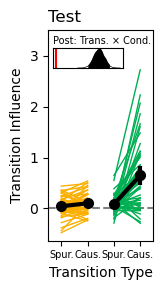

In [87]:
# Each participants average reward on old and novel target trials
plot_df = mean_trans_influence_test_df[['id', 'sem_congruent', 'transition', 'coef']]
plot_df['transition'] = plot_df['transition'].map({
    'spurious': 0,
    'causal': 1
}).astype(int)
plot_df['group'] = plot_df['sem_congruent']*2 + plot_df['transition']

fig, ax = plt.subplots(figsize=(2, 3))

# Plot data
ax.axhline(0, c='.5', linestyle='--')
sns.lineplot(
    data = plot_df,
    x = 'group',
    y = 'coef',
    hue = 'id',
    palette = condition_id_palette,
    linewidth = 1,
    errorbar = None,
    ax = ax
)

for i, hdi in enumerate(posterior_summaries[:, 1:]):
    ax.vlines(np.unique(plot_df['group'])[i], *hdi, color='black', linewidth=3)
ax.plot(
    np.unique(plot_df['group'])[:2],
    posterior_summaries[:2, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)
ax.plot(
    np.unique(plot_df['group'])[2:],
    posterior_summaries[2:, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)

# Format
ax.set_xlim([np.min(np.unique(plot_df['group'])) - .5, np.max(np.unique(plot_df['group'])) + .5])
ax.get_legend().remove()
ax.set_xticks(np.unique(plot_df['group']))
ax.set_xticklabels(['Spur.', 'Caus.']*2, fontsize=7)

ax.set_xlabel('Transition Type')
ax.set_ylabel('Transition Influence')
ax.set_ylim([None, 3.5])
ax.set_title('Test', loc='left')
set_axis_ratio(ax, 2)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '70%',
    height = '20%',
    bbox_to_anchor =  (-.17, 0.47, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_16.posterior['sem_congruent:transition'].values.flatten(),
    label = 'Post: Trans. × Cond.',
    label_loc = 'left',
    chance_color = 'red'
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/transition-influence-test-by-condition.pdf')

### 1-step transition influence only

In [88]:
idx = trans_influence_test_df['n_steps'] == 1
model_df = trans_influence_test_df.loc[idx]
model_17 = bmb.Model(
    "coef ~ sem_congruent*transition + (1|action) + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_17 = model_17.fit(
    random_seed = 17,
    tune = 4000,
    draws = 2000,
    target_accept = .95
)
az.summary(fitted_17)

Output()

There were 35 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],-0.010,0.146,-0.364,0.303,0.003,0.003,2259.0,1515.0,1.0
1|action[2],-0.070,0.147,-0.436,0.236,0.003,0.003,2162.0,1740.0,1.0
1|action[3],0.073,0.146,-0.263,0.394,0.003,0.003,2209.0,1442.0,1.0
1|action_sigma,0.224,0.236,0.000,0.708,0.007,0.006,1600.0,1818.0,1.0
1|id[300],-0.178,0.196,-0.567,0.207,0.002,0.002,12485.0,5138.0,1.0
...,...,...,...,...,...,...,...,...,...
Intercept,0.058,0.158,-0.305,0.393,0.004,0.003,2108.0,1571.0,1.0
sem_congruent,0.063,0.096,-0.129,0.247,0.002,0.001,2979.0,4676.0,1.0
sem_congruent:transition[causal],0.755,0.086,0.585,0.920,0.001,0.001,6295.0,6002.0,1.0
sigma,0.533,0.017,0.500,0.564,0.000,0.000,8241.0,5763.0,1.0


In [76]:
# Generate means and HDIs of each data group
posterior_summaries = []
for condition in [0, 1]:
    for transition in ['spurious', 'causal']:
        idx = (
            (mean_trans_influence_test_df['sem_congruent'] == condition) &
            (mean_trans_influence_test_df['transition'] == transition) &
            (mean_trans_influence_test_df['n_steps'] == 1)
            
        )
        model = bmb.Model('coef ~ 1', mean_trans_influence_test_df.loc[idx])
        fitted = model.fit(random_seed=4793)
        post_values = az.summary(fitted)
        post_values = post_values[['mean', 'hdi_2.5%', 'hdi_97.5%']].values[0]
        posterior_summaries.append(post_values)
posterior_summaries = np.array(posterior_summaries)

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/2034060425.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


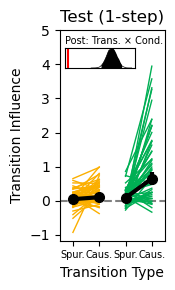

In [89]:
# Each participants average reward on old and novel target trials
idx = mean_trans_influence_test_df['n_steps'] == 1
plot_df = mean_trans_influence_test_df.loc[idx][['id', 'sem_congruent', 'transition', 'coef']]
plot_df['transition'] = plot_df['transition'].map({
    'spurious': 0,
    'causal': 1
}).astype(int)
plot_df['group'] = plot_df['sem_congruent']*2 + plot_df['transition']

fig, ax = plt.subplots(figsize=(2, 3))

# Plot data
ax.axhline(0, c='.5', linestyle='--')
sns.lineplot(
    data = plot_df,
    x = 'group',
    y = 'coef',
    hue = 'id',
    palette = condition_id_palette,
    linewidth = 1,
    ax = ax
)

for i, hdi in enumerate(posterior_summaries[:, 1:]):
    ax.vlines(np.unique(plot_df['group'])[i], *hdi, color='black', linewidth=3)
ax.plot(
    np.unique(plot_df['group'])[:2],
    posterior_summaries[:2, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)
ax.plot(
    np.unique(plot_df['group'])[2:],
    posterior_summaries[2:, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)

# Format
ax.set_xlim([np.min(np.unique(plot_df['group'])) - .5, np.max(np.unique(plot_df['group'])) + .5])
ax.get_legend().remove()
ax.set_xticks(np.unique(plot_df['group']))
ax.set_xticklabels(['Spur.', 'Caus.']*2, fontsize=7)

ax.set_xlabel('Transition Type')
ax.set_ylabel('Transition Influence')
ax.set_ylim([None, 5])
ax.set_title('Test (1-step)', loc='left')
set_axis_ratio(ax, 2)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '70%',
    height = '20%',
    bbox_to_anchor =  (-.17, 0.47, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_17.posterior['sem_congruent:transition'].values.flatten(),
    label = 'Post: Trans. × Cond.',
    label_loc = 'left',
    chance_color = 'red'
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/transition-influence-test-by-condition-1step.pdf')

### 2-step transition influence only

In [90]:
idx = trans_influence_test_df['n_steps'] == 2
model_df = trans_influence_test_df.loc[idx]
model_18 = bmb.Model(
    "coef ~ sem_congruent*transition + (1|action) + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_18 = model_18.fit(
    random_seed = 18,
    tune = 4000,
    draws = 2000,
    target_accept = .95
)
az.summary(fitted_18)

Output()

There were 61 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],-0.001,0.041,-0.094,0.088,0.002,0.002,1067.0,621.0,1.0
1|action[2],0.007,0.041,-0.084,0.098,0.002,0.002,1095.0,675.0,1.0
1|action[3],0.001,0.041,-0.081,0.097,0.002,0.002,1131.0,656.0,1.0
1|action_sigma,0.048,0.066,0.000,0.180,0.003,0.002,1362.0,598.0,1.0
1|id[300],-0.109,0.118,-0.328,0.129,0.001,0.001,8934.0,6017.0,1.0
...,...,...,...,...,...,...,...,...,...
Intercept,0.025,0.054,-0.081,0.132,0.002,0.002,1349.0,645.0,1.0
sem_congruent,0.015,0.055,-0.092,0.123,0.001,0.001,3013.0,4525.0,1.0
sem_congruent:transition[causal],0.253,0.056,0.143,0.367,0.001,0.001,4521.0,5067.0,1.0
sigma,0.347,0.011,0.325,0.368,0.000,0.000,6312.0,5671.0,1.0


In [91]:
# Generate means and HDIs of each data group
posterior_summaries = []
for condition in [0, 1]:
    for transition in ['spurious', 'causal']:
        idx = (
            (mean_trans_influence_test_df['sem_congruent'] == condition) &
            (mean_trans_influence_test_df['transition'] == transition) &
            (mean_trans_influence_test_df['n_steps'] == 2)
            
        )
        model = bmb.Model('coef ~ 1', mean_trans_influence_test_df.loc[idx])
        fitted = model.fit(random_seed=4793)
        post_values = az.summary(fitted)
        post_values = post_values[['mean', 'hdi_2.5%', 'hdi_97.5%']].values[0]
        posterior_summaries.append(post_values)
posterior_summaries = np.array(posterior_summaries)

Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/630899882.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


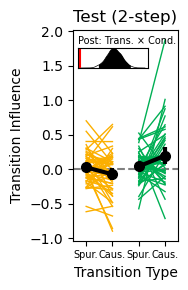

In [92]:
# Each participants average reward on old and novel target trials
idx = mean_trans_influence_test_df['n_steps'] == 2
plot_df = mean_trans_influence_test_df.loc[idx][['id', 'sem_congruent', 'transition', 'coef']]
plot_df['transition'] = plot_df['transition'].map({
    'spurious': 0,
    'causal': 1
}).astype(int)
plot_df['group'] = plot_df['sem_congruent']*2 + plot_df['transition']

fig, ax = plt.subplots(figsize=(2, 3))

# Plot data
ax.axhline(0, c='.5', linestyle='--')
sns.lineplot(
    data = plot_df,
    x = 'group',
    y = 'coef',
    hue = 'id',
    palette = condition_id_palette,
    linewidth = 1,
    ax = ax
)

for i, hdi in enumerate(posterior_summaries[:, 1:]):
    ax.vlines(np.unique(plot_df['group'])[i], *hdi, color='black', linewidth=3)
ax.plot(
    np.unique(plot_df['group'])[:2],
    posterior_summaries[:2, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)
ax.plot(
    np.unique(plot_df['group'])[2:],
    posterior_summaries[2:, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)

# Format
ax.set_xlim([np.min(np.unique(plot_df['group'])) - .5, np.max(np.unique(plot_df['group'])) + .5])
ax.get_legend().remove()
ax.set_xticks(np.unique(plot_df['group']))
ax.set_xticklabels(['Spur.', 'Caus.']*2, fontsize=7)

ax.set_xlabel('Transition Type')
ax.set_ylabel('Transition Influence')
#ax.set_ylim([None, 14.5])
ax.set_title('Test (2-step)', loc='left')
set_axis_ratio(ax, 2)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '70%',
    height = '20%',
    bbox_to_anchor =  (-.17, 0.47, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_18.posterior['sem_congruent:transition'].values.flatten(),
    label = 'Post: Trans. × Cond.',
    label_loc = 'left',
    chance_color = 'red'
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/transition-influence-test-by-condition-2step.pdf')

## Does the difference between semantic congruent and incongruent change across training?

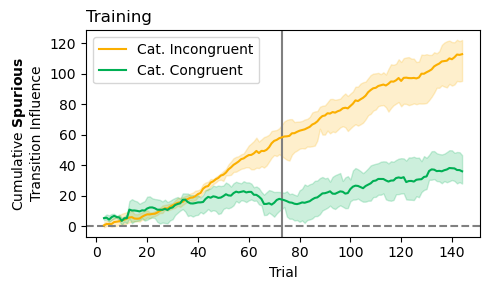

In [90]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.axvline(int(144/2) + 1, c='.5')
ax.axhline(0, c='.5', linestyle='--')
#plt.plot([1, 144], [1, 144], ls='--', c='0.5')
idx = trans_influence_trial_df['transition'] == 'spurious'
sns.lineplot(
    data = trans_influence_trial_df.loc[idx],
    x = 't',
    y = 'cumulative_coef',
    hue = 'sem_congruent',
    palette = CONDITION_COLORS
)

ax.set_title('Training', loc='left')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, ['Cat. Incongruent', 'Cat. Congruent'])
ax.set_xlabel('Trial')
ax.set_ylabel(r'Cumulative $\bf{Spurious}$' + '\nTransition Influence')
fig.tight_layout()
plt.savefig(f'{FIG_PATH}/cumulative-spurious-transition-influence.pdf', dpi=300)

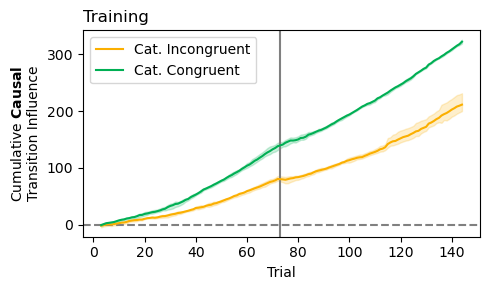

In [89]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.axvline(int(144/2) + 1, c='.5')
ax.axhline(0, c='.5', linestyle='--')
#plt.plot([1, 144], [1, 144], ls='--', c='0.5')
idx = trans_influence_trial_df['transition'] == 'causal'
sns.lineplot(
    data = trans_influence_trial_df.loc[idx],
    x = 't',
    y = 'cumulative_coef',
    hue = 'sem_congruent',
    palette = CONDITION_COLORS
)
ax.set_title('Training', loc='left')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles, ['Cat. Incongruent', 'Cat. Congruent'])
ax.set_xlabel('Trial')
ax.set_ylabel(r'Cumulative $\bf{Causal}$' + '\nTransition Influence')
fig.tight_layout()
plt.savefig(f'{FIG_PATH}/cumulative-causal-transition-influence.pdf', dpi=300)

## Relationship between transition influence and frequency sensitivity

### Training

In [25]:
model_df = trans_influence_df[['id', 'action', 'transition', 'coef']]
model_df = pd.pivot(
    data = model_df,
    index = ['id', 'action'],
    columns = 'transition',
    values = 'coef'
)
model_df = model_df.reset_index()
model_df = pd.merge(
    model_df,
    training_df[['id', 't', 'freq', 'reward']]
)

model_20 = bmb.Model(
    "reward ~ freq*spurious*causal + (1|id) + (1|action)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_20 = model_20.fit(
    random_seed = 20,
    target_accept = .9,
    tune = 2000,
    draws = 2000
)

# Summary table
az.summary(fitted_20, round_to=6)[-9:]

Output()

There were 36 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,1.212176,0.027882,1.159293,1.267890,0.001169,0.000827,567.163764,1426.411605,1.006684
causal,0.066951,0.010200,0.047656,0.087333,0.000349,0.000247,851.514377,1776.033777,1.001365
freq,0.020135,0.010744,-0.000644,0.041707,0.000151,0.000106,5095.980240,5127.006063,1.000291
freq:causal,0.006744,0.003679,-0.000327,0.013924,0.000055,0.000039,4497.811185,5267.178045,1.000326
freq:spurious,0.047337,0.012714,0.023161,0.072746,0.000254,0.000180,2505.280948,4218.382055,1.000499
freq:spurious:causal,0.002460,0.002746,-0.002771,0.007954,0.000056,0.000040,2413.877773,4358.445129,1.000976
sigma,0.674934,0.002273,0.670403,0.679185,0.000024,0.000017,8850.867078,5870.892851,0.999832
spurious,-0.043456,0.013663,-0.070623,-0.017361,0.000322,0.000230,1797.178914,2714.397951,1.001142
spurious:causal,0.002751,0.002767,-0.002672,0.008102,0.000064,0.000045,1874.257701,3271.804625,1.000453


In [94]:
# Summarize data
plot_df = model_df[['id', 'action', 'spurious', 'causal', 'freq', 'reward']]
plot_df = plot_df.groupby(['id', 'action', 'spurious', 'causal', 'freq'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()
plot_df = plot_df[['id', 'spurious', 'causal', 'freq', 'reward']]
plot_df = plot_df.groupby(['id', 'freq'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
posterior_summaries_spurious = data_summary(
    plot_df,
    ['freq'],
    'reward',
    x_var = 'spurious',
    seed = 2332,
    fname = f'{FIG_PATH}/stats/freq-by-spurious-influence.pkl'
)

# Get mean and 95% HDI for causal influence -> reward gain
posterior_summaries_causal = data_summary(
    plot_df,
    ['freq'],
    'reward',
    x_var = 'causal',
    seed = 4342,
    fname = f'{FIG_PATH}/stats/freq-by-causal-influence.pkl'
)

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/3547143258.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


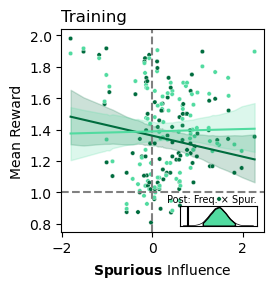

In [95]:
fig, ax = plt.subplots(figsize=(3, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(1, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'spurious',
    y = 'reward',
    hue = 'freq',
    palette = FREQUENCY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for freq in [0, 1]:
    post = posterior_summaries_spurious[freq]

    # Plot mean
    ax.plot(*post['mean'], color=FREQUENCY_COLORS[freq], label=freq)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['freq'] == freq, 'spurious'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=FREQUENCY_COLORS[freq])
    
# Format
ax.set_xlabel(r'$\bf{Spurious}$ Influence')
ax.set_ylabel('Mean Reward')
ax.get_legend().remove()
ax.set_title('Training', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.05, -.32, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_20.posterior['freq:spurious'].values.flatten(),
    label = 'Post: Freq. × Spur.',
    label_loc = 'right',
    chance_color = 'black',
    color = FREQUENCY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/training-reward-by-spurious-influence.pdf')

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/1969023181.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


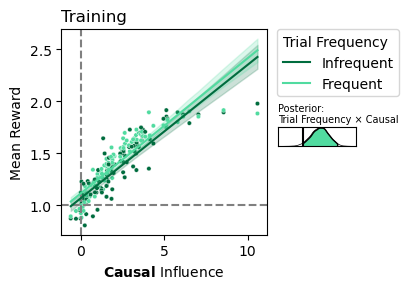

In [96]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(1, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'causal',
    y = 'reward',
    hue = 'freq',
    palette = FREQUENCY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for freq in [0, 1]:
    post = posterior_summaries_causal[freq]

    # Plot mean
    ax.plot(*post['mean'], color=FREQUENCY_COLORS[freq], label=freq)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['freq'] == freq, 'causal'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=FREQUENCY_COLORS[freq])
    
# Format
ax.set_xlabel(r'$\bf{Causal}$ Influence')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(
    handles[-2:],
    ['Infrequent', 'Frequent'],
    loc = (1.05, .675),
    title = 'Trial Frequency',
    alignment = 'left'
)
ax.set_title('Training', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .08, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_20.posterior['freq:causal'].values.flatten(),
    label = 'Posterior:\nTrial Frequency × Causal',
    label_loc = 'left',
    chance_color = 'black',
    color = FREQUENCY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/training-reward-by-causal-influence.pdf', bbox_inches='tight')

### Test

In [26]:
model_df = trans_influence_df[['id', 'action', 'transition', 'coef']]
model_df = pd.pivot(
    data = model_df,
    index = ['id', 'action'],
    columns = 'transition',
    values = 'coef'
)
model_df = model_df.reset_index()
model_df = pd.merge(
    model_df,
    test_df.loc[test_df['old'], ['id', 't', 'freq', 'reward']]
)

model_21 = bmb.Model(
    "reward ~ freq*spurious*causal + (1|id) + (1|action)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_21 = model_21.fit(
    random_seed = 21,
    target_accept = .95,
    tune = 4000,
    draws = 4000
)

# Summary table
az.summary(fitted_21)[-9:]

Output()

There were 78 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.995,0.036,0.923,1.063,0.001,0.0,3640.0,4235.0,1.0
causal,0.086,0.010,0.065,0.106,0.000,0.0,4674.0,6373.0,1.0
freq,0.088,0.025,0.038,0.136,0.000,0.0,11625.0,11413.0,1.0
freq:causal,0.013,0.008,-0.003,0.030,0.000,0.0,10766.0,11153.0,1.0
freq:spurious,0.023,0.030,-0.035,0.083,0.000,0.0,8496.0,10102.0,1.0
freq:spurious:causal,-0.002,0.006,-0.014,0.010,0.000,0.0,8609.0,10688.0,1.0
sigma,0.679,0.006,0.667,0.689,0.000,0.0,20762.0,11432.0,1.0
spurious,-0.054,0.028,-0.108,0.001,0.000,0.0,6278.0,7510.0,1.0
spurious:causal,0.012,0.006,0.000,0.022,0.000,0.0,6759.0,8956.0,1.0


In [27]:
# Summarize data
plot_df = model_df[['id', 'action', 'spurious', 'causal', 'freq', 'reward']]
plot_df = plot_df.groupby(['id', 'action', 'spurious', 'causal', 'freq'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()
plot_df = plot_df[['id', 'spurious', 'causal', 'freq', 'reward']]
plot_df = plot_df.groupby(['id', 'freq'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
posterior_summaries_spurious = data_summary(
    plot_df,
    ['freq'],
    'reward',
    x_var = 'spurious',
    seed = 2190,
    fname = f'{FIG_PATH}/stats/test-freq-by-spurious-influence.pkl'
)

# Get mean and 95% HDI for causal influence -> reward gain
posterior_summaries_causal = data_summary(
    plot_df,
    ['freq'],
    'reward',
    x_var = 'causal',
    seed = 239823,
    fname = f'{FIG_PATH}/stats/test-freq-by-causal-influence.pkl'
)

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_79761/1788453194.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


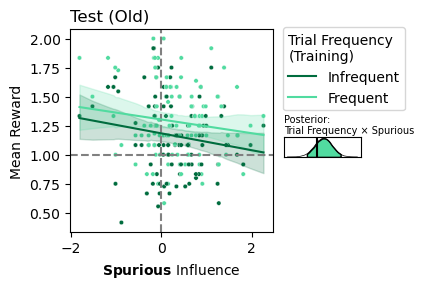

In [28]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(1, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'spurious',
    y = 'reward',
    hue = 'freq',
    palette = FREQUENCY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for freq in [0, 1]:
    post = posterior_summaries_spurious[freq]

    # Plot mean
    ax.plot(*post['mean'], color=FREQUENCY_COLORS[freq], label=freq)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['freq'] == freq, 'spurious'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=FREQUENCY_COLORS[freq])
    
# Format
ax.set_xlabel(r'$\bf{Spurious}$ Influence')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(
    handles[-2:],
    ['Infrequent', 'Frequent'],
    loc = (1.05, .6),
    title = 'Trial Frequency\n(Training)',
    alignment = 'left'
)
ax.set_title('Test (Old)', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .02, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_21.posterior['freq:spurious'].values.flatten(),
    label = 'Posterior:\nTrial Frequency × Spurious',
    label_loc = 'left',
    chance_color = 'black',
    color = FREQUENCY_COLORS[1]
)

plt.tight_layout()
plt.savefig(f'{FIG_PATH}/test-reward-by-spurious-influence.pdf', bbox_inches='tight')

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_79761/1633356261.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


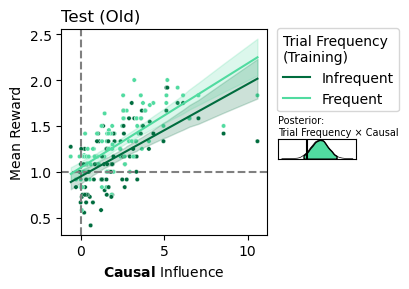

In [29]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(1, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'causal',
    y = 'reward',
    hue = 'freq',
    palette = FREQUENCY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for freq in [0, 1]:
    post = posterior_summaries_causal[freq]

    # Plot mean
    ax.plot(*post['mean'], color=FREQUENCY_COLORS[freq], label=freq)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['freq'] == freq, 'causal'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=FREQUENCY_COLORS[freq])
    
# Format
ax.set_xlabel(r'$\bf{Causal}$ Influence')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(
    handles[-2:],
    ['Infrequent', 'Frequent'],
    loc = (1.05, .6),
    title = 'Trial Frequency\n(Training)',
    alignment = 'left'
)
ax.set_title('Test (Old)', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .02, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_21.posterior['freq:causal'].values.flatten(),
    label = 'Posterior:\nTrial Frequency × Causal',
    label_loc = 'left',
    chance_color = 'black',
    color = FREQUENCY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-reward-by-causal-influence.pdf', bbox_inches='tight')

## Transition influence on generalization

In [101]:
model_df = trans_influence_df[['id', 'action', 'transition', 'coef']]
model_df = pd.pivot(
    data = model_df,
    index = ['id', 'action'],
    columns = 'transition',
    values = 'coef'
)
model_df = model_df.reset_index()
idx = test_df['n_transitions_to_target'] == 1
model_df = pd.merge(
    model_df,
    test_df.loc[idx, ['id', 't', 'novel_target', 'novel_options', 'reward']]
)

model_22 = bmb.Model(
    "reward ~ novel_target*spurious*causal + novel_options*spurious*causal + (1|id) + (1|action)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_22 = model_22.fit(
    random_seed = 22,
    target_accept = .9,
    tune = 2000,
    draws = 2000
)

# Summary table
az.summary(fitted_22)[-9:]

Output()

There were 37 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
novel_options:spurious,0.018,0.012,-0.005,0.041,0.0,0.0,2264.0,3406.0,1.0
novel_options:spurious:causal,-0.001,0.002,-0.006,0.004,0.0,0.0,2175.0,2962.0,1.0
novel_target,0.002,0.009,-0.015,0.021,0.0,0.0,4152.0,5215.0,1.0
novel_target:causal,0.002,0.003,-0.004,0.009,0.0,0.0,3150.0,4566.0,1.0
novel_target:spurious,-0.032,0.012,-0.056,-0.010,0.0,0.0,2503.0,3784.0,1.0
novel_target:spurious:causal,0.006,0.003,0.001,0.011,0.0,0.0,2240.0,3577.0,1.0
sigma,0.481,0.002,0.478,0.485,0.0,0.0,8765.0,6025.0,1.0
spurious,-0.005,0.016,-0.036,0.025,0.0,0.0,1866.0,3249.0,1.0
spurious:causal,0.000,0.003,-0.006,0.007,0.0,0.0,1742.0,3128.0,1.0


In [102]:
# Summarize data
plot_df = model_df[[
    'id',
    'action',
    'spurious',
    'causal',
    'novel_target',
    'reward'
]]
plot_df = plot_df.groupby(['id',
    'action',
    'spurious',
    'causal',
    'novel_target'
])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()
plot_df = plot_df[[
    'id',
    'spurious',
    'causal',
    'novel_target',
    'reward'
]]
plot_df = plot_df.groupby([
    'id',
    'novel_target'
])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
novtarget_by_spurious_summary = data_summary(
    plot_df,
    ['novel_target'],
    'reward',
    x_var = 'spurious',
    seed = 4523,
    fname = f'{FIG_PATH}/stats/novtarget-by-spurious-influence.pkl'
)

# Get mean and 95% HDI for causal influence -> reward gain
novtarget_by_causal_summary = data_summary(
    plot_df,
    ['novel_target'],
    'reward',
    x_var = 'causal',
    seed = 6543,
    fname = f'{FIG_PATH}/stats/novtarget-by-causal-influence.pkl'
)

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/3267865972.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


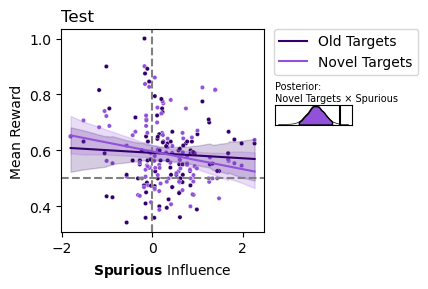

In [103]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(.5, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'spurious',
    y = 'reward',
    hue = 'novel_target',
    palette = NOVELTY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for novel in [0, 1]:
    post = novtarget_by_spurious_summary[novel]

    # Plot mean
    ax.plot(*post['mean'], color=NOVELTY_COLORS[novel], label=novel)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['novel_target'] == novel, 'spurious'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=NOVELTY_COLORS[novel])
    
# Format
ax.set_xlabel(r'$\bf{Spurious}$ Influence')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Old Targets', 'Novel Targets'], loc=(1.05, .775))
ax.set_title('Test', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .18, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_22.posterior['novel_target:spurious'].values.flatten(),
    label = 'Posterior:\nNovel Targets × Spurious',
    label_loc = 'left',
    chance_color = 'black',
    color = NOVELTY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-novel-target-by-spurious-influence.pdf', bbox_inches='tight')

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/2498059605.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


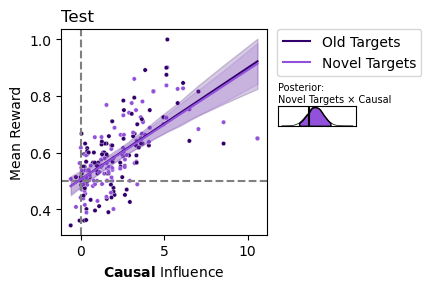

In [104]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(.5, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'causal',
    y = 'reward',
    hue = 'novel_target',
    palette = NOVELTY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for novel in [0, 1]:
    post = novtarget_by_causal_summary[novel]

    # Plot mean
    ax.plot(*post['mean'], color=NOVELTY_COLORS[novel], label=novel)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['novel_target'] == novel, 'causal'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=NOVELTY_COLORS[novel])
    
# Format
ax.set_xlabel(r'$\bf{Causal}$ Influence')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Old Targets', 'Novel Targets'], loc=(1.05, .775))
ax.set_title('Test', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .18, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_22.posterior['novel_target:causal'].values.flatten(),
    label = 'Posterior:\nNovel Targets × Causal',
    label_loc = 'left',
    chance_color = 'black',
    color = NOVELTY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-novel-target-by-causal-influence.pdf', bbox_inches='tight')

In [105]:
# Summarize data
plot_df = model_df[[
    'id',
    'action',
    'spurious',
    'causal',
    'novel_options',
    'reward'
]]
plot_df = plot_df.groupby([
    'id',
    'action',
    'spurious',
    'causal',
    'novel_options'
])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()
plot_df = plot_df[[
    'id',
    'spurious',
    'causal',
    'novel_options',
    'reward'
]]
plot_df = plot_df.groupby([
    'id',
    'novel_options'
])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
novoptions_by_spurious_summary = data_summary(
    plot_df,
    ['novel_options'],
    'reward',
    x_var = 'spurious',
    seed = 2534,
    fname = f'{FIG_PATH}/stats/novoptions-by-spurious-influence.pkl'
)

# Get mean and 95% HDI for causal influence -> reward gain
novoptions_by_causal_summary = data_summary(
    plot_df,
    ['novel_options'],
    'reward',
    x_var = 'causal',
    seed = 3443,
    fname = f'{FIG_PATH}/stats/novoptions-by-causal-influence.pkl'
)

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/734581797.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


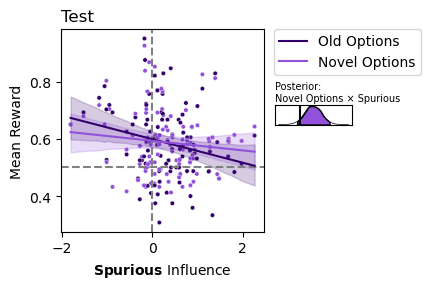

In [106]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(.5, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'spurious',
    y = 'reward',
    hue = 'novel_options',
    palette = NOVELTY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for novel in [0, 1]:
    post = novoptions_by_spurious_summary[novel]

    # Plot mean
    ax.plot(*post['mean'], color=NOVELTY_COLORS[novel], label=novel)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['novel_options'] == novel, 'spurious'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=NOVELTY_COLORS[novel])
    
# Format
ax.set_xlabel(r'$\bf{Spurious}$ Influence')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Old Options', 'Novel Options'], loc=(1.05, .775))
ax.set_title('Test', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .18, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_22.posterior['novel_options:spurious'].values.flatten(),
    label = 'Posterior:\nNovel Options × Spurious',
    label_loc = 'left',
    chance_color = 'black',
    color = NOVELTY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-novel-options-by-spurious-influence.pdf', bbox_inches='tight')

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/3410056139.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


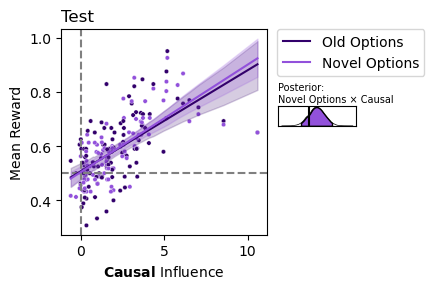

In [107]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(.5, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'causal',
    y = 'reward',
    hue = 'novel_options',
    palette = NOVELTY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for novel in [0, 1]:
    post = novoptions_by_causal_summary[novel]

    # Plot mean
    ax.plot(*post['mean'], color=NOVELTY_COLORS[novel], label=novel)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['novel_options'] == novel, 'causal'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=NOVELTY_COLORS[novel])
    
# Format
ax.set_xlabel(r'$\bf{Causal}$ Influence')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Old Options', 'Novel Options'], loc=(1.05, .775))
ax.set_title('Test', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .18, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_22.posterior['novel_options:causal'].values.flatten(),
    label = 'Posterior:\nNovel Options × Causal',
    label_loc = 'left',
    chance_color = 'black',
    color = NOVELTY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-novel-options-by-causal-influence.pdf', bbox_inches='tight')

## Behavior by causal-bias parameter fit

### Transition influence by causal-bias parameter fit

In [30]:
# Select participants with feature-based fits only
idx = trans_influence_df['model_class'] == 'ff'
model_df = trans_influence_df.loc[idx]

# Code so that causal = 1
model_df['transition'] = model_df['transition'] == 'causal'

# Fit model with segmentation 
model_23 = bmb.Model(
    "coef ~ bias_magnitude*transition + (1|action)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_23 = model_23.fit(
    random_seed = 23,
    tune = 2000,
    draws = 2000,
    target_accept = .95
)

# Results
az.summary(fitted_23)

Output()

There were 42 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],-0.015,0.157,-0.421,0.308,0.007,0.006,1013.0,389.0,1.00
1|action[2],-0.007,0.158,-0.354,0.376,0.007,0.006,1058.0,422.0,1.00
1|action[3],-0.020,0.153,-0.413,0.299,0.006,0.005,980.0,439.0,1.00
1|action_sigma,0.203,0.271,0.000,0.779,0.011,0.008,997.0,609.0,1.01
Intercept,0.560,0.192,0.125,0.939,0.007,0.006,1206.0,457.0,1.00
bias_magnitude,-0.752,0.214,-1.175,-0.336,0.004,0.003,3061.0,3574.0,1.00
bias_magnitude:transition,4.178,0.308,3.555,4.755,0.006,0.004,2587.0,2911.0,1.00
sigma,1.279,0.047,1.192,1.373,0.001,0.000,4907.0,4645.0,1.00
transition,0.732,0.183,0.372,1.095,0.003,0.002,2902.0,3556.0,1.00


In [18]:
plot_df = model_df[['id', 'bias_magnitude', 'transition', 'coef']]
plot_df = plot_df.groupby(['id', 'bias_magnitude', 'transition'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
coef_by_bias_summary = data_summary(
    plot_df,
    ['transition'],
    'coef',
    x_var = 'bias_magnitude',
    seed = 32344,
    fname = f'{FIG_PATH}/stats/coef-by-bias.pkl'
)

### Training frequency sensitivity by causal-bias parameter fit

In [72]:
# Select participants with feature-based fits only
idx = training_df['model_class'] == 'ff'
model_df = training_df.loc[idx, ['id', 'bias_magnitude', 'freq', 'reward']]

# Fit model with segmentation 
model_24 = bmb.Model(
    'reward ~ bias_magnitude*freq + (1|id)',
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_24 = model_24.fit(
    random_seed = 24,
    tune = 2000,
    draws = 2000,
    target_accept = .95
)

# Results
az.summary(fitted_24)

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id[300],-0.198,0.060,-0.308,-0.071,0.001,0.001,4192.0,5360.0,1.0
1|id[302],0.105,0.060,-0.016,0.218,0.001,0.001,3706.0,4937.0,1.0
1|id[304],0.227,0.057,0.117,0.340,0.001,0.001,5004.0,4909.0,1.0
1|id[307],0.151,0.056,0.043,0.263,0.001,0.001,5562.0,5850.0,1.0
1|id[308],-0.092,0.062,-0.212,0.030,0.001,0.001,3220.0,4379.0,1.0
...,...,...,...,...,...,...,...,...,...
Intercept,1.222,0.033,1.157,1.284,0.001,0.001,1416.0,2649.0,1.0
bias_magnitude,0.494,0.056,0.382,0.604,0.001,0.001,1469.0,2469.0,1.0
bias_magnitude:freq,-0.058,0.033,-0.126,0.004,0.000,0.000,5921.0,5660.0,1.0
freq,0.071,0.020,0.033,0.111,0.000,0.000,6247.0,5924.0,1.0


In [20]:
# Each participants average reward on frequent and infrequent trials
plot_df = model_df.groupby(['id', 'freq', 'bias_magnitude'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
freq_by_bias_summary = data_summary(
    plot_df,
    ['freq'],
    'reward',
    x_var = 'bias_magnitude',
    seed = 54322,
    fname = f'{FIG_PATH}/stats/freq-by-bias.pkl'
)

### Test (old) frequency sensitivity by causal-bias parameter fit

In [112]:
# Select participants with feature-based fits only
idx = (
    (test_df['model_class'] == 'ff') &
    test_df['old']
)
model_df = test_df.loc[idx, ['id', 'bias_magnitude', 'freq', 'reward']]

# Fit model with segmentation 
model_25 = bmb.Model(
    'reward ~ bias_magnitude*freq + (1|id)',
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_25 = model_25.fit(
    random_seed = 25,
    tune = 2000,
    draws = 2000,
    target_accept = .95
)

# Results
az.summary(fitted_25)

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id[300],-0.009,0.106,-0.213,0.202,0.001,0.001,11224.0,5858.0,1.0
1|id[302],0.197,0.107,-0.003,0.412,0.001,0.001,9461.0,6435.0,1.0
1|id[304],0.306,0.112,0.095,0.529,0.001,0.001,8971.0,6062.0,1.0
1|id[307],0.103,0.106,-0.098,0.313,0.001,0.001,9138.0,5556.0,1.0
1|id[308],0.118,0.109,-0.098,0.332,0.001,0.001,9611.0,4672.0,1.0
...,...,...,...,...,...,...,...,...,...
Intercept,1.054,0.043,0.973,1.143,0.001,0.001,3734.0,5216.0,1.0
bias_magnitude,0.494,0.074,0.354,0.644,0.001,0.001,3456.0,5145.0,1.0
bias_magnitude:freq,-0.069,0.078,-0.223,0.081,0.001,0.001,5706.0,6416.0,1.0
freq,0.169,0.046,0.075,0.257,0.001,0.000,5993.0,5957.0,1.0


In [113]:
# Each participants average reward on frequent and infrequent trials
plot_df = model_df.groupby(['id', 'freq', 'bias_magnitude'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
test_freq_by_bias_summary = data_summary(
    plot_df,
    ['freq'],
    'reward',
    x_var = 'bias_magnitude',
    seed = 53423,
    fname = f'{FIG_PATH}/stats/test-freq-by-bias.pkl'
)

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/294567920.py:444: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi = az.hdi(post_preds)


/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/2434321133.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


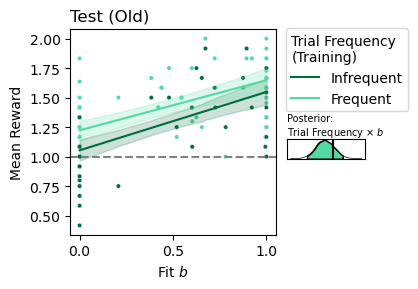

In [114]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(1, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'bias_magnitude',
    y = 'reward',
    hue = 'freq',
    palette = FREQUENCY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for freq in [0, 1]:
    post = test_freq_by_bias_summary[freq]

    # Plot mean
    ax.plot(*post['mean'], color=FREQUENCY_COLORS[freq], label=freq)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['freq'] == freq, 'bias_magnitude'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=FREQUENCY_COLORS[freq])
    
# Format
ax.set_xlabel(r'Fit $\it{b}$')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(
    handles[-2:],
    ['Infrequent', 'Frequent'],
    loc = (1.05, .6),
    title = 'Trial Frequency\n(Training)',
    alignment = 'left'
)
ax.set_title('Test (Old)', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .02, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_25.posterior['bias_magnitude:freq'].values.flatten(),
    label = 'Posterior:\nTrial Frequency × ' + r'$\it{b}$',
    label_loc = 'left',
    chance_color = 'black',
    color = FREQUENCY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-reward-by-causal-bias.pdf', bbox_inches='tight')

### Generalization performance by causal-bias parameter fit

In [21]:
idx = (
    (test_df['model_class'] == 'ff') &
    (test_df['n_transitions_to_target'] == 1)
)
model_df = test_df.loc[idx, [
    'id',
    'bias_magnitude',
    'novel_target',
    'novel_options',
    'reward'
]]
model_df = model_df.reset_index(drop=True)

model_26 = bmb.Model(
    "reward ~ novel_target*bias_magnitude + novel_options*bias_magnitude + (1|id)",
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_26 = model_26.fit(
    random_seed = 26,
    tune = 2000,
    draws = 2000,
)
az.summary(fitted_26)[-7:]

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.570,0.025,0.523,0.620,0.000,0.0,5675.0,6468.0,1.0
bias_magnitude,0.169,0.042,0.093,0.258,0.001,0.0,5389.0,5761.0,1.0
novel_options,-0.011,0.018,-0.045,0.024,0.000,0.0,7987.0,6855.0,1.0
novel_options:bias_magnitude,0.011,0.031,-0.046,0.073,0.000,0.0,7351.0,6173.0,1.0
novel_target,0.007,0.018,-0.030,0.042,0.000,0.0,7671.0,6360.0,1.0
novel_target:bias_magnitude,-0.020,0.030,-0.079,0.039,0.000,0.0,7644.0,6741.0,1.0
sigma,0.473,0.004,0.465,0.480,0.000,0.0,17344.0,6214.0,1.0


In [22]:
# Each participants average reward on test trials with old versus novel targets trials
plot_df = model_df.groupby(['id', 'novel_options', 'novel_target', 'bias_magnitude'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()

# Get mean and 95% HDI for spurious influence -> reward gain
novel_options_by_bias_summary = data_summary(
    plot_df,
    ['novel_options'],
    'reward',
    x_var = 'bias_magnitude',
    seed = 2243,
    fname = f'{FIG_PATH}/stats/novel-options-by-bias.pkl'
)

# Get mean and 95% HDI for spurious influence -> reward gain
novel_target_by_bias_summary = data_summary(
    plot_df,
    ['novel_target'],
    'reward',
    x_var = 'bias_magnitude',
    seed = 2243,
    fname = f'{FIG_PATH}/stats/novel-target-by-bias.pkl'
)

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/781916317.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


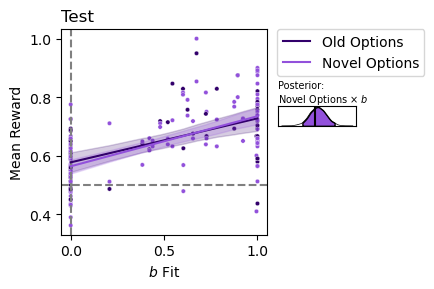

In [117]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(.5, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'bias_magnitude',
    y = 'reward',
    hue = 'novel_options',
    palette = NOVELTY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for novel in [0, 1]:
    post = novel_options_by_bias_summary[novel]

    # Plot mean
    ax.plot(*post['mean'], color=NOVELTY_COLORS[novel], label=novel)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['novel_options'] == novel, 'bias_magnitude'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=NOVELTY_COLORS[novel])
    
# Format
ax.set_xlabel(r'$\it{b}$ Fit')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Old Options', 'Novel Options'], loc=(1.05, .775))
ax.set_title('Test', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .18, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_26.posterior['novel_options:bias_magnitude'].values.flatten(),
    label = 'Posterior:\nNovel Options × ' + r'$\it{b}$',
    label_loc = 'left',
    chance_color = 'black',
    color = NOVELTY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-novel-options-by-causal-bias.pdf', bbox_inches='tight')

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_95603/3663239991.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


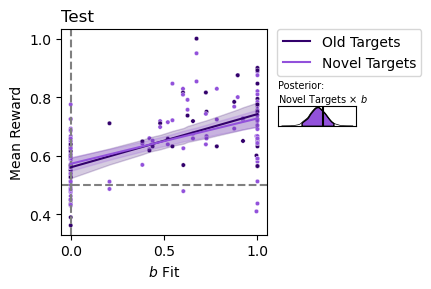

In [118]:
fig, ax = plt.subplots(figsize=(4, 3))

# Plot average reward by spurious transition influence and frequency
ax.axhline(.5, c='.5', linestyle='--')
ax.axvline(0, c='.5', linestyle='--')
sns.scatterplot(
    data = plot_df,
    x = 'bias_magnitude',
    y = 'reward',
    hue = 'novel_target',
    palette = NOVELTY_COLORS,
    s = 10,
    zorder = 0,
    ax = ax
)

# Plot means and 95% HDI lines
for novel in [0, 1]:
    post = novel_target_by_bias_summary[novel]

    # Plot mean
    ax.plot(*post['mean'], color=NOVELTY_COLORS[novel], label=novel)

    # Plot 95% HDI
    x = np.unique(plot_df.loc[plot_df['novel_target'] == novel, 'bias_magnitude'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=NOVELTY_COLORS[novel])
    
# Format
ax.set_xlabel(r'$\it{b}$ Fit')
ax.set_ylabel('Mean Reward')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Old Targets', 'Novel Targets'], loc=(1.05, .775))
ax.set_title('Test', loc='left')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '40%',
    height = '20%',
    bbox_to_anchor =  (.52, .18, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_26.posterior['novel_target:bias_magnitude'].values.flatten(),
    label = 'Posterior:\nNovel Targets × ' + r'$\it{b}$',
    label_loc = 'left',
    chance_color = 'black',
    color = NOVELTY_COLORS[1]
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/test-novel-target-by-causal-bias.pdf', bbox_inches='tight')

### Composition spurious predictiveness by causal-bias parameter

In [23]:
idx = (
    (test_df['spurious_trial'] == 1) &
    (test_df['model_class'] == 'ff')
)
model_df = test_df.loc[idx, ['id', 'bias_magnitude', 'comp_spur_pred']]
model_28 = bmb.Model(
    'comp_spur_pred ~ bias_magnitude + (1|id)',
    model_df,
    family = 'gaussian',
    link = 'identity'
)
fitted_28 = model_28.fit(
    random_seed = 28,
    tune = 2000,
    draws = 2000
)
az.summary(fitted_28)[-3:]


Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.940,0.034,0.870,1.005,0.000,0.000,10783.0,5296.0,1.0
bias_magnitude,-0.020,0.057,-0.129,0.091,0.001,0.001,11251.0,5880.0,1.0
sigma,0.717,0.017,0.684,0.751,0.000,0.000,12921.0,5577.0,1.0


In [24]:
# Each participant's average composition spurious predictiveness 
plot_df = model_df.groupby(['id', 'bias_magnitude'])
plot_df = plot_df.mean()
plot_df = plot_df.reset_index()
plot_df['group'] = 1

# Get mean and 95% HDI for spurious influence -> reward gain
spur_pred_by_bias_summary = data_summary(
    plot_df,
    ['group'],
    'comp_spur_pred',
    x_var = 'bias_magnitude',
    seed = 443232,
    fname = f'{FIG_PATH}/stats/spur-pred-by-bias.pkl'
)[1]


### Plot together

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_79761/2237535591.py:169: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


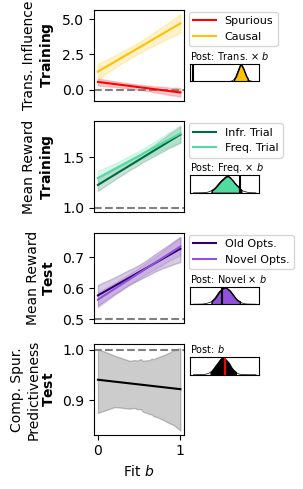

In [73]:
fig, axs = plt.subplots(4, 1, figsize=(2.5, 5))

### Plot causal and spurious transition influence by causal-bias parameter fit

ax = axs[0]
ax.axhline(0, c='.5', linestyle='--')

# Plot means and 95% HDI lines
for transition in [0, 1]: # spurious, causal
    post = coef_by_bias_summary[transition]

    transition = ['spurious', 'causal'][transition]

    # Plot mean
    ax.plot(*post['mean'], color=TRANSITION_COLORS[transition], label=transition)

    # Plot 95% HDI
    x = np.unique(plot_df['bias_magnitude'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=TRANSITION_COLORS[transition])
    
# Format
ax.set_xlabel(None)
ax.set_xticks([])
#ax.set_ylabel('Trans. Influence\n(Training)')
ax.set_ylabel('Trans. Influence\n' + r'$\bf{Training}$')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Spurious', 'Causal'], fontsize=8, loc=(1.05, .6))
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '80%',
    height = '40%',
    bbox_to_anchor =  (.95, 0, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_23.posterior['bias_magnitude:transition'].values.flatten(),
    label = r'Post: Trans. × $\it{b}$',
    label_loc = 'left',
    chance_color = 'black',
    color = TRANSITION_COLORS['causal']
)

### Plot training frequency sensitivity by causal-bias parameter fit

ax = axs[1]
ax.axhline(1, c='.5', linestyle='--')

# Plot means and 95% HDI lines
for freq in [0, 1]:
    post = freq_by_bias_summary[freq]

    # Plot mean
    ax.plot(*post['mean'], color=FREQUENCY_COLORS[freq], label=freq)

    # Plot 95% HDI
    x = np.unique(plot_df['bias_magnitude'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=FREQUENCY_COLORS[freq])
    
# Format
ax.set_xlabel(None)
ax.set_xticks([])
ax.set_ylabel('Mean Reward\n' + r'$\bf{Training}$')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Infr. Trial', 'Freq. Trial'], fontsize=8, loc=(1.05, .6))
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '80%',
    height = '40%',
    bbox_to_anchor =  (.95, 0, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_24.posterior['bias_magnitude:freq'].values.flatten(),
    label = r'Post: Freq. × $\it{b}$',
    label_loc = 'left',
    chance_color = 'black',
    color = FREQUENCY_COLORS[1]
)



### Plot options generalization by causal-bias parameter fit 

ax = axs[2]
ax.axhline(.5, c='.5', linestyle='--')

# Plot means and 95% HDI lines
for novel in [0, 1]:
    post = novel_options_by_bias_summary[novel]
    
    # Plot mean
    ax.plot(*post['mean'], color=NOVELTY_COLORS[novel], label=novel)

    # Plot 95% HDI
    x = np.unique(plot_df['bias_magnitude'])
    ax.fill_between(x, *post['hdi'].T, alpha=.2, color=NOVELTY_COLORS[novel])
    
# Format
ax.set_ylabel('Mean Reward\n' + r'$\bf{Test}$')
handles = ax.get_legend_handles_labels()[0]
ax.legend(handles[-2:], ['Old Opts.', 'Novel Opts.'], fontsize=8, loc=(1.05, .6))
ax.set_xticks([])
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '80%',
    height = '40%',
    bbox_to_anchor =  (.95, 0, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_26.posterior['novel_options:bias_magnitude'].values.flatten(),
    label = r'Post: Novel × $\it{b}$',
    label_loc = 'left',
    chance_color = 'black',
    color = NOVELTY_COLORS[1]
)



### Plot composition spurious predictiveness by causal-bias parameter fit

ax = axs[3]

# Plot average reward by spurious transition influence and frequency
ax.axhline(1, c='.5', linestyle='--')

# Plot mean
ax.plot(*spur_pred_by_bias_summary['mean'], color='k')

# Plot 95% HDI
x = np.unique(plot_df['bias_magnitude'])
ax.fill_between(x, *spur_pred_by_bias_summary['hdi'].T, alpha=.2, color='k')
    
# Format
ax.set_xlabel(r'Fit $\it{b}$')
ax.set_ylabel('Comp. Spur.\nPredictiveness\n' + r'$\bf{Test}$')
set_axis_ratio(ax)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '80%',
    height = '40%',
    bbox_to_anchor =  (.95, .45, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_28.posterior['bias_magnitude'].values.flatten(),
    label = r'Post: $\it{b}$',
    label_loc = 'left',
    chance_color = 'red'
)


# Save
fig.tight_layout()
plt.savefig(f'{FIG_PATH}/bias-predictions.pdf', bbox_inches='tight')

## Do we see differences in transition influence by condition within participants fit by a conjunctive model?

In [46]:
idx = trans_influence_df['model_class'] == 'ss'
model_29 = bmb.Model(
    "coef ~ sem_congruent*transition + (1|action) + (1|id)",
    trans_influence_df.loc[idx],
    family = 'gaussian',
    link = 'identity'
)
fitted_29 = model_29.fit(
    random_seed = 29,
    tune = 4000,
    draws = 2000,
    target_accept = .95
)
az.summary(fitted_29)

Output()

There were 175 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|action[1],0.083,0.290,-0.537,0.795,0.017,0.014,609.0,254.0,1.01
1|action[2],-0.100,0.292,-0.716,0.623,0.018,0.016,542.0,264.0,1.01
1|action[3],0.025,0.289,-0.502,0.797,0.018,0.015,569.0,256.0,1.01
1|action_sigma,0.387,0.527,0.000,1.561,0.038,0.030,467.0,196.0,1.01
1|id[313],-0.166,0.257,-0.690,0.316,0.005,0.004,2394.0,2841.0,1.00
1|id[316],-1.143,0.280,-1.677,-0.586,0.004,0.003,4407.0,5357.0,1.00
1|id[317],-0.274,0.256,-0.780,0.227,0.005,0.003,2956.0,5366.0,1.00
1|id[320],0.147,0.259,-0.320,0.687,0.005,0.004,2312.0,3383.0,1.00
1|id[321],0.173,0.259,-0.322,0.683,0.005,0.003,3131.0,5460.0,1.00
1|id[325],0.120,0.265,-0.404,0.635,0.005,0.004,3212.0,2643.0,1.00


In [48]:
# Generate means and HDIs of each data group
posterior_summaries = []
for condition in [0, 1]:
    for transition in ['spurious', 'causal']:
        idx = (
            (mean_trans_influence_df['sem_congruent'] == condition) &
            (mean_trans_influence_df['transition'] == transition) &
            (mean_trans_influence_df['model_class'] == 'ss')
        )
        model = bmb.Model('coef ~ 1', mean_trans_influence_df.loc[idx])
        fitted = model.fit(random_seed=4793)
        post_values = az.summary(fitted)
        post_values = post_values[['mean', 'hdi_2.5%', 'hdi_97.5%']].values[0]
        posterior_summaries.append(post_values)
posterior_summaries = np.array(posterior_summaries)

Output()

Output()

Output()

Output()

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_68710/3779797464.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


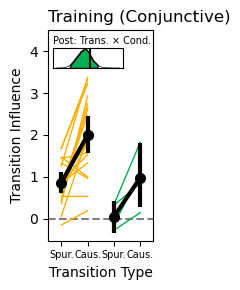

In [53]:
# Each participants average reward on old and novel target trials
idx = mean_trans_influence_df['model_class'] == 'ss'
plot_df = mean_trans_influence_df.loc[idx, ['id', 'sem_congruent', 'transition', 'coef']]
plot_df['transition'] = plot_df['transition'].map({
    'spurious': 0,
    'causal': 1
}).astype(int)
plot_df['group'] = plot_df['sem_congruent']*2 + plot_df['transition']

fig, ax = plt.subplots(figsize=(2, 3))

# Plot data
ax.axhline(0, c='.5', linestyle='--')
sns.lineplot(
    data = plot_df,
    x = 'group',
    y = 'coef',
    hue = 'id',
    palette = condition_id_palette,
    linewidth = 1,
    ax = ax
)

for i, hdi in enumerate(posterior_summaries[:, 1:]):
    ax.vlines(np.unique(plot_df['group'])[i], *hdi, color='black', linewidth=3)
ax.plot(
    np.unique(plot_df['group'])[:2],
    posterior_summaries[:2, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)
ax.plot(
    np.unique(plot_df['group'])[2:],
    posterior_summaries[2:, 0],
    '-ok',
    linewidth = 3,
    markersize = 7
)

# Format
ax.set_xlim([np.min(np.unique(plot_df['group'])) - .5, np.max(np.unique(plot_df['group'])) + .5])
ax.get_legend().remove()
ax.set_xticks(np.unique(plot_df['group']))
ax.set_xticklabels(['Spur.', 'Caus.']*2, fontsize=7)

ax.set_xlabel('Transition Type')
ax.set_ylabel('Transition Influence')
ax.set_ylim([None, 4.5])
ax.set_title('Training (Conjunctive)', loc='left')
set_axis_ratio(ax, 2)

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '70%',
    height = '20%',
    bbox_to_anchor =  (-.17, 0.47, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_29.posterior['sem_congruent:transition'].values.flatten(),
    label = 'Post: Trans. × Cond.',
    label_loc = 'left',
    chance_color = 'black',
    color = CONDITION_COLORS[1],
)

fig.tight_layout()
plt.savefig(f'{FIG_PATH}/transition-influence-by-condition-ss.pdf')

In [54]:
idx = training_df['model_class'] == 'ss'
model_30 = bmb.Model(
    'reward ~ sem_congruent + (1|id)',
    training_df.loc[idx, ['id', 'sem_congruent', 'reward']],
    family = 'gaussian',
    link = 'identity'
)
fitted_30 = model_30.fit(
    random_seed = 30,
    draws = 2000,
    tune = 2000
)
az.summary(fitted_30)

Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
1|id[313],-0.196,0.069,-0.329,-0.059,0.001,0.001,4527.0,5872.0,1.0
1|id[316],-0.323,0.068,-0.458,-0.191,0.001,0.001,4473.0,5391.0,1.0
1|id[317],-0.080,0.068,-0.210,0.052,0.001,0.001,4456.0,5380.0,1.0
1|id[320],0.126,0.068,-0.009,0.257,0.001,0.001,4475.0,5330.0,1.0
1|id[321],0.157,0.069,0.024,0.293,0.001,0.001,4788.0,5779.0,1.0
1|id[325],0.096,0.068,-0.035,0.231,0.001,0.001,4379.0,5378.0,1.0
1|id[326],0.054,0.099,-0.143,0.247,0.002,0.001,3697.0,4728.0,1.0
1|id[329],0.151,0.068,0.019,0.285,0.001,0.001,4325.0,5182.0,1.0
1|id[332],0.176,0.068,0.048,0.314,0.001,0.001,4528.0,5890.0,1.0
1|id[337],-0.015,0.068,-0.151,0.113,0.001,0.001,4299.0,5066.0,1.0


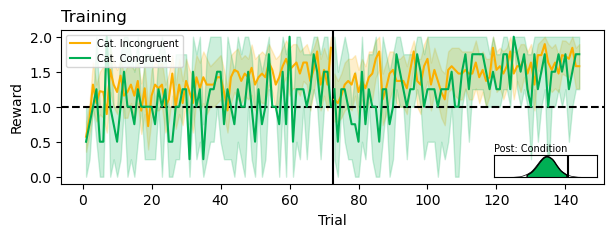

In [55]:
fig, ax = plt.subplots(figsize=(7, 2))

ax.axhline(1, color='black', linestyle='--')
ax.axvline(int(np.max(training_df['t'])/2) + 0.5, color='black')
for block in np.unique(training_df['block']):
    idx = (
        (training_df['block'] == block) &
        (training_df['model_class'] == 'ss')
        )
    sns.lineplot(
        data = training_df.loc[idx],
        x = 't',
        y = 'reward',
        hue = 'sem_congruent',
        palette = CONDITION_COLORS,
        ax = ax
    )
handles = ax.get_legend_handles_labels()[0]
ax.legend(
    handles[:2],
    ['Cat. Incongruent', 'Cat. Congruent'],
    fontsize = 7,
    loc = 'upper left'
    )
ax.set_xlabel('Trial')
ax.set_ylabel('Reward')
ax.set_title('Training', loc='left')

# Inset interaction posterior plot with HDI
inset_ax = inset_axes(
    ax,
    width = '20%',
    height = '30%',
    bbox_to_anchor =  (.05, -0.25, .95, 0.48),
    bbox_transform = ax.transAxes
)
plot_hdi(
    inset_ax,
    fitted_30.posterior['sem_congruent'].values.flatten(),
    label = 'Post: Condition',
    label_loc = 'left',
    chance_color = 'k',
    color = CONDITION_COLORS[1]
)


fig.savefig(
    f'{FIG_PATH}/training_curve-ss.pdf',
    bbox_inches = 'tight',
    dpi = 300
    )